# Práctica DL para Finanzas — Avance 5 (Capítulo 11) y resultados finales
**Indicadores técnicos como variables, filtro técnico, evaluación única de TE y pronóstico futuro**

| Campo | Valor |
|---|---|
| Equipo | _Figueroa Manríquez Elizabeth Priscilla_ |
| Activo | BTC/USDT diario, MEXC spot (mismo archivo crudo de los avances anteriores) |
| Objetivo | $y_t = P_{t+1}/P_t - 1$ |
| Indicadores añadidos | Distancia a la SMA de 20 cierres y volatilidad de 20 rendimientos (los recomendados por el protocolo) |

Lo que pide la hoja del Avance 5 y dónde está en este notebook:

| Requisito | Sección |
|---|---|
| Al menos dos indicadores, calculados solo con historia hasta $t$, documentados (qué representan, ventana, fórmula, primera fecha válida) y sin relleno hacia atrás | 3 |
| Redundancia y correlaciones | 3.2 |
| **A.** Modelo con rezagos vs **B.** el mismo modelo con indicadores: MAE y RMSE en las mismas fechas de VA | 4 |
| Predicciones casi constantes y diagnóstico del entrenamiento | 4.4 |
| **C.** Estrategia solo con el pronóstico vs **D.** la misma estrategia con el filtro "cierre > SMA20": rendimiento neto, drawdown y operaciones en VA | 5 |
| Versión final elegida con VA, configuración congelada y **TE evaluado una sola vez** | 6 y 7 |
| `predicciones_TE.csv`, `simulacion.csv` y resultados en TR, VA y TE | 7 |
| Pronóstico del siguiente periodo no observado (`prediccion_futura.csv`) | 8 |
| Seguimiento: ¿el indicador aporta información o solo complejidad? Conclusión sobre la hipótesis técnica | 9 |
| Ejecución desde una sesión limpia y lista de entregables | 10 |

**COT (opcional):** no se usa. El reporte COT de la CFTC es semanal, se publica con retraso y cubre futuros, no el spot de MEXC. Para usarlo sin fuga habría que alinearlo por su fecha real de publicación, y el protocolo lo deja como opcional.

**Antes de ejecutar:**
1. Activen la GPU T4.
2. Deben existir en Drive los resultados de los avances 2 y 3.
3. Para probar la ejecución desde una sesión limpia: `Entorno de ejecución → Desconectar y borrar entorno de ejecución`, y después `Ejecutar todas`.

## 0. Entorno, configuración, versiones y bitácora

In [1]:
# === 0.1 Montar Drive y crear carpetas persistentes ===
import os, sys, json, time, random, hashlib, platform, subprocess, warnings
from datetime import datetime, timezone
from pathlib import Path

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/DL_Finanzas')
else:
    BASE = Path(os.environ.get('DL_FIN_BASE', './DL_Finanzas'))

DIRS = {k: BASE / v for k, v in {
    'crudos': 'datos/originales',
    'procesados': 'datos/procesados',
    'modelos': 'modelos',
    'resultados': 'resultados',
    'figuras': 'figuras',
    'evidencia': 'evidencia_t4',
    'bitacora': 'bitacora',
}.items()}
for carpeta in DIRS.values():
    carpeta.mkdir(parents=True, exist_ok=True)
print('En Colab:', EN_COLAB)
print('Carpeta del proyecto:', BASE.resolve())

Mounted at /content/drive
En Colab: True
Carpeta del proyecto: /content/drive/MyDrive/DL_Finanzas


In [2]:
# === 0.2 Librerías, configuración, semilla y versiones ===
import numpy as np
import pandas as pd
import requests, joblib, sklearn, matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

CONFIG = {
    # --- Datos y partición: idénticos al Avance 1 ---
    'MERCADO': 'Criptomonedas',
    'SIMBOLO': 'BTCUSDT',
    'MONEDA_BASE': 'BTC',
    'MONEDA_COTIZADA': 'USDT',
    'INTERVALO': '1d',
    'FUENTE': 'MEXC Spot API v3, endpoint público GET /api/v3/klines',
    'URL_KLINES': 'https://api.mexc.com/api/v3/klines',
    'INICIO_DESCARGA_UTC': '2017-01-01',
    'REUTILIZAR_CRUDO': True,      # usa el mismo crudo del Avance 1 (mismas fechas TR/VA/TE)
    'ARCHIVO_LOCAL': None,
    'MIN_OBS': 1500,
    'HUECO_MAX_DIAS': 7,
    'N_REZAGOS': 20,
    'PROP_TR': 0.70,
    'PROP_VA': 0.15,
    'SEMILLA': 42,
    # --- Redes del capítulo 8 ---
    'REQUIERE_T4': True,           # si no hay T4, se detiene el entrenamiento profundo (regla del protocolo)
    'PERDIDA': 'mean_squared_error',   # como en el libro
    'OPTIMIZADOR': 'Adam',             # como en el libro
    'TASA_APRENDIZAJE': 1e-3,
    'LOTE': 32,                    # el libro sugiere empezar con 32
    'MAX_EPOCAS': 300,
    'PACIENCIA': 25,               # épocas sin mejorar la pérdida de VA antes de detener
    'NEURONAS_CANDIDATAS': [10, 20, 40],   # 20 = configuración del libro; solo cambia el número de neuronas
    'SEMILLAS': [42, 123, 2024],   # repetición de la mejor configuración de cada red
    # --- Capítulo 9 ---
    'CV_VENTANAS': 3,              # evaluaciones con ventana expansiva dentro de TR
    'CV_INICIO': 0.50,             # el primer entrenamiento usa el primer 50 % de TR; el resto se divide en 3 bloques
    'CV_VAL_INTERNA': 0.15,        # último 15 % de cada entrenamiento: solo para la parada temprana
    'REDES_CV': ['lstm', 'mlp'],   # redes que se reentrenan en cada ventana (mejor configuración del Avance 2)
    'CUANTILES_UMBRAL': [0.10, 0.25, 0.50, 0.75, 0.90],  # umbrales = cuantiles de las predicciones del modelo en TR
    'UMBRALES_RESPALDO': [0.0005, 0.001, 0.002, 0.003, 0.005],  # solo si el modelo no tiene predicciones positivas en TR
    'CAPITAL_INICIAL': 100_000,    # USDT
    'COSTO': 0.001,                # 0.10 % por compra y por venta (supuesto académico)
    # --- Capítulo 11 ---
    'INDICADORES_MODELO': ['dist_sma20', 'vol20'],   # los dos indicadores que entran al modelo B
    'REENTRENAR_CAP11': False,     # False: si ya existen los modelos del cap. 11 en Drive, se cargan (resultados reproducibles)
    'UMBRAL_CASI_CONSTANTE': 0.05, # desv. est. de la predicción / desv. est. del real por debajo de esto = casi constante
    'DESCARGAR_DATOS_RECIENTES': True,   # para el pronóstico futuro; no modifica TR, VA ni TE
    'DIAS_RECIENTES': 150,
    'META_RENDIMIENTO_TE': 0.20,   # +20 % pedido por el profesor; solo se reporta, nunca se usa para elegir
}
SEMILLA = CONFIG['SEMILLA']
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ['PYTHONHASHSEED'] = str(SEMILLA)

import tensorflow as tf
import keras
from keras import layers
info_build = tf.sysconfig.get_build_info()
VERSIONES = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'cuda_build': info_build.get('cuda_version', 'n/d'),
    'cudnn_build': info_build.get('cudnn_version', 'n/d'),
    'plataforma': platform.platform(),
    'semilla_base': SEMILLA,
    'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS['resultados'] / 'versiones_entorno_cap11.json', 'w') as f:
    json.dump(VERSIONES, f, indent=2)
pd.Series(VERSIONES)

,0
python,3.13.16
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
tensorflow,2.21.0
keras,3.13.2
cuda_build,12.5.1
cudnn_build,9
plataforma,Linux-6.6.159+-x86_64-with-glibc2.39


In [3]:
# === 0.3 Excepciones específicas y bitácora de errores ===
# Regla: nada de "except: pass". Cada error se captura por tipo, se explica y se registra.
class ErrorPractica(Exception):
    'Error base de la práctica.'
class DescargaError(ErrorPractica):
    'La fuente no respondió o respondió con un error.'
class DatosVaciosError(ErrorPractica):
    'No hay datos, o no alcanzan el mínimo requerido.'
class FechaDuplicadaError(ErrorPractica):
    'Fechas repetidas que no se pueden resolver con la regla documentada.'
class ValorInvalidoError(ErrorPractica):
    'Valores no finitos, no positivos o archivo alterado.'
class DimensionError(ErrorPractica):
    'Formas o columnas distintas a las esperadas.'
class FugaInformacionError(ErrorPractica):
    'Se detectó uso de información futura o del conjunto reservado.'

RUTA_BITACORA = DIRS['bitacora'] / 'bitacora_errores.csv'

def registrar_evento(etapa, error, causa, accion, verificacion):
    'Agrega una fila: fecha | etapa | error | causa | acción correctiva | resultado de la verificación.'
    fila = pd.DataFrame([{
        'fecha': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'etapa': etapa, 'error': error, 'causa': causa,
        'accion_correctiva': accion, 'resultado_verificacion': verificacion,
    }])
    fila.to_csv(RUTA_BITACORA, mode='a', header=not RUTA_BITACORA.exists(), index=False)
    print(f'[BITÁCORA] {etapa} | {error} | {causa} | {accion} | {verificacion}')

In [4]:
# === 0.4 Excepciones adicionales del capítulo 8 ===
class ParticionDistintaError(ErrorPractica):
    'Las particiones no coinciden con las del Avance 1.'
class EntrenamientoError(ErrorPractica):
    'Fallo del entrenamiento (pérdida no finita, pesos no restaurados, GPU no usada).'

## 1. Evidencia de la GPU T4

In [5]:
# === 1. Evidencia de T4 ===
def verificar_t4():
    ts = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    ev = {'fecha_utc': ts, 'entorno_colab': EN_COLAB, 'semilla': SEMILLA}

    # 1) nvidia-smi
    try:
        salida = subprocess.run(['nvidia-smi'], capture_output=True, text=True,
                                timeout=30, check=True).stdout
        print(salida)
        (DIRS['evidencia'] / f'nvidia_smi_{ts}.txt').write_text(salida)
        consulta = subprocess.run(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            capture_output=True, text=True, timeout=30, check=True).stdout.strip()
        ev['nvidia_smi_gpu'] = consulta
    except FileNotFoundError:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no existe: el entorno no tiene GPU NVIDIA'
    except subprocess.CalledProcessError as e:
        ev['nvidia_smi_gpu'] = f'nvidia-smi falló: {e.stderr.strip()}'
    except subprocess.TimeoutExpired:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no respondió en 30 s'

    # 2) y 3) TensorFlow reconoce la GPU y ejecuta una operación en ella
    import tensorflow as tf
    tf.random.set_seed(SEMILLA)
    ev['tensorflow'] = tf.__version__
    ev['tf_construido_con_cuda'] = bool(tf.test.is_built_with_cuda())
    gpus = tf.config.list_physical_devices('GPU')
    ev['tf_gpus'] = [g.name for g in gpus]
    ev['operacion_dispositivo'] = 'sin GPU'
    if gpus:
        detalles = tf.config.experimental.get_device_details(gpus[0])
        ev['tf_nombre_gpu'] = detalles.get('device_name', '')
        ev['compute_capability'] = str(detalles.get('compute_capability', ''))
        with tf.device('/GPU:0'):
            a = tf.random.normal((4000, 4000))
            _ = tf.matmul(a, a).numpy()            # calentamiento
            t0 = time.perf_counter()
            c = tf.matmul(a, a)
            _ = c.numpy()                          # fuerza la sincronización
            ev['matmul_4000x4000_s'] = round(time.perf_counter() - t0, 4)
        ev['operacion_dispositivo'] = c.device
    nombre = f"{ev.get('tf_nombre_gpu', '')} {ev.get('nvidia_smi_gpu', '')}"
    ev['T4_OK'] = ('T4' in nombre) and ('GPU' in ev['operacion_dispositivo'])

    with open(DIRS['evidencia'] / f'evidencia_t4_{ts}.json', 'w') as f:
        json.dump(ev, f, indent=2)
    if not ev['T4_OK']:
        registrar_evento('entorno', 'T4 ausente o GPU no utilizada',
                         f"GPU detectada: {nombre.strip() or 'ninguna'}",
                         'Cap. 7 continúa en CPU (modelos clásicos). No entrenar MLP/LSTM; reprogramar sesión con T4.',
                         'pendiente')
    return ev

EVIDENCIA_T4 = verificar_t4()
print(json.dumps(EVIDENCIA_T4, indent=2))
print('\n>>> T4 verificada y usada por TensorFlow:', EVIDENCIA_T4['T4_OK'])

Thu Nov 12 14:24:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Datos, partición, referencias, modelos del Avance 2, motor de simulación y regla del Avance 3

In [6]:
# === 2. Descarga o carga del archivo crudo ===
COLS_MEXC = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume']
MS_DIA = 86_400_000

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

def _get_json(url, params, max_reintentos=5, espera_inicial=1.0):
    espera, ultimo_error = espera_inicial, None
    for intento in range(1, max_reintentos + 1):
        try:
            r = requests.get(url, params=params, timeout=20)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
            ultimo_error = f'{type(e).__name__}: {e}'
        else:
            if r.status_code == 429 or r.status_code >= 500:
                ultimo_error = f'HTTP {r.status_code}: {r.text[:200]}'
            elif r.status_code >= 400:
                raise DescargaError(f'MEXC rechazó la solicitud {params}: HTTP {r.status_code} {r.text[:300]}. '
                                    'Revise el símbolo (ej. BTCUSDT) y el intervalo (1d).')
            else:
                try:
                    return r.json()
                except ValueError as e:
                    raise DescargaError(f'MEXC no devolvió JSON válido: {r.text[:200]}') from e
        print(f'  intento {intento}/{max_reintentos} fallido ({ultimo_error}); nuevo intento en {espera:.0f} s')
        time.sleep(espera)
        espera *= 2
    raise DescargaError(f'Sin respuesta válida de MEXC tras {max_reintentos} intentos. Último error: {ultimo_error}')

def descargar_klines_mexc(simbolo, intervalo, inicio_utc, dias_por_bloque=200, pausa=0.25):
    # MEXC entrega como máximo ~500 velas por solicitud aunque se pidan 1000.
    # Por eso se piden bloques de 200 días y, si un bloque llega incompleto, se continúa desde la última vela recibida.
    ahora_ms = int(time.time() * 1000)
    s = int(pd.Timestamp(inicio_utc, tz='UTC').timestamp() * 1000)
    filas, solicitudes, incompletos = [], 0, []
    while s < ahora_ms:
        e = min(s + dias_por_bloque * MS_DIA - 1, ahora_ms)
        datos = _get_json(CONFIG['URL_KLINES'], {'symbol': simbolo, 'interval': intervalo,
                                                 'startTime': s, 'endTime': e, 'limit': 1000})
        solicitudes += 1
        if not isinstance(datos, list):
            raise DescargaError(f'MEXC devolvió un objeto inesperado (¿error?): {str(datos)[:300]}')
        if datos:
            filas.extend(datos)
            ultimo_open = max(int(k[0]) for k in datos)
            primero_open = min(int(k[0]) for k in datos)
            if filas and len(filas) > len(datos) and primero_open - s > 2 * MS_DIA:
                incompletos.append(f"{pd.to_datetime(s, unit='ms').date()}: faltan velas al inicio del bloque")
            siguiente = ultimo_open + MS_DIA          # continuar justo después de la última vela recibida
            if ultimo_open + MS_DIA <= e:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(ultimo_open, unit='ms').date()}: "
                      f"{len(datos)} velas (bloque incompleto, se continúa desde ahí)")
            else:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(e, unit='ms').date()}: {len(datos)} velas")
            s = max(siguiente, s + MS_DIA)
        else:
            s = e + 1
        time.sleep(pausa)
    if not filas:
        raise DatosVaciosError(f'MEXC no devolvió velas para {simbolo} {intervalo} desde {inicio_utc}. '
                               'Verifique que el par existe en MEXC spot y la conectividad.')
    if incompletos:
        print('ADVERTENCIA: posibles bloques truncados por la API:', incompletos)
    anchos = {len(f) for f in filas}
    if min(anchos) < 7:
        raise DimensionError(f'Velas con {sorted(anchos)} campos; se esperaban al menos 7 (open_time … close_time).')
    df = pd.DataFrame([f[:8] for f in filas])
    df.columns = COLS_MEXC[:df.shape[1]]
    return df, {'descarga_ms': ahora_ms, 'bloques': solicitudes, 'avisos_truncamiento': incompletos}

VERSION_DESCARGA = 2   # v2: bloques de 200 días con continuación; los crudos v1 (bloques de 1000 días) quedaron truncados

SIM, INTV = CONFIG['SIMBOLO'], CONFIG['INTERVALO']
ARCH_CRUDO = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo.csv'
ARCH_META = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo_meta.json'

META_PREVIA = json.load(open(ARCH_META)) if ARCH_META.exists() else {}
if META_PREVIA and META_PREVIA.get('version_descarga', 1) < VERSION_DESCARGA and not CONFIG['ARCHIVO_LOCAL']:
    print('El crudo guardado proviene de la descarga v1 (bloques truncados por MEXC): se descargará de nuevo y se respaldará el anterior.')
    registrar_evento('descarga', 'Crudo truncado por límite de velas de MEXC',
                     'La API devuelve ~500 velas por solicitud; bloques de 1000 días dejaron huecos de 500 días',
                     'Descarga v2: bloques de 200 días con continuación; crudo v1 respaldado', 'ver auditoría de la nueva descarga')
    usar_previo = False
else:
    usar_previo = True
if CONFIG['REUTILIZAR_CRUDO'] and usar_previo and ARCH_CRUDO.exists() and ARCH_META.exists():
    META = META_PREVIA
    if sha256_archivo(ARCH_CRUDO) != META['sha256']:
        raise ValorInvalidoError(f'{ARCH_CRUDO.name} no coincide con su SHA-256 registrado: el archivo crudo fue modificado. '
                                 'Restaure el original o descargue de nuevo con REUTILIZAR_CRUDO=False.')
    crudo = pd.read_csv(ARCH_CRUDO)
    print(f"Archivo crudo reutilizado: {ARCH_CRUDO.name} (descargado {META['fecha_descarga_utc']}), {len(crudo)} filas")
elif CONFIG['ARCHIVO_LOCAL']:
    ruta_local = Path(CONFIG['ARCHIVO_LOCAL'])
    if not ruta_local.exists():
        raise DatosVaciosError(f'La copia local {ruta_local} no existe.')
    crudo = pd.read_csv(ruta_local)
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': f'Copia local identificada: {ruta_local}', 'simbolo': SIM, 'intervalo': INTV,
            'fecha_descarga_utc': datetime.fromtimestamp(ruta_local.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': int(ruta_local.stat().st_mtime * 1000),
            'filas_recibidas': len(crudo), 'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    registrar_evento('descarga', 'Uso de copia local', 'Descarga no disponible',
                     f'Se cargó {ruta_local} y se registró su huella', 'trazabilidad conservada')
else:
    if ARCH_CRUDO.exists():  # respaldo: nunca se sobrescribe un crudo previo
        sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        ARCH_CRUDO.rename(ARCH_CRUDO.with_name(f'{ARCH_CRUDO.stem}_respaldo_{sello}.csv'))
        if ARCH_META.exists():
            ARCH_META.rename(ARCH_META.with_name(f'{ARCH_META.stem}_respaldo_{sello}.json'))
    try:
        crudo, info = descargar_klines_mexc(SIM, INTV, CONFIG['INICIO_DESCARGA_UTC'])
    except (DescargaError, DatosVaciosError, DimensionError) as e:
        registrar_evento('descarga', type(e).__name__, f'{CONFIG["FUENTE"]} | {SIM} | {e}',
                         'Flujo detenido. Revisar conectividad/símbolo o usar ARCHIVO_LOCAL identificado.', 'sin datos')
        raise
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': CONFIG['FUENTE'], 'url': CONFIG['URL_KLINES'], 'simbolo': SIM, 'intervalo': INTV,
            'parametros': {'startTime_inicial': CONFIG['INICIO_DESCARGA_UTC'], 'limit': 1000, 'dias_por_bloque': 200},
            'version_descarga': VERSION_DESCARGA, 'avisos_truncamiento': info['avisos_truncamiento'],
            'fecha_descarga_utc': datetime.fromtimestamp(info['descarga_ms'] / 1000, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': info['descarga_ms'], 'bloques': info['bloques'],
            'filas_recibidas': len(crudo), 'columnas': list(crudo.columns),
            'zona_horaria': 'Marcas de tiempo en milisegundos Unix (UTC)',
            'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    print(f'Crudo guardado: {ARCH_CRUDO} ({len(crudo)} filas)')

crudo.head()

Archivo crudo reutilizado: BTCUSDT_1d_mexc_crudo.csv (descargado 2026-11-05T14:21:43+00:00), 3298 filas


,open_time,open,high,low,close,volume,close_time,quote_volume
0,1508947200000,5712.00,5990.00,5400.00,5875.91,1489.138175,1509033600000,8.509059e+06
1,1509033600000,5876.00,5948.52,5669.93,5739.00,523.927660,1509120000000,3.066163e+06
2,1509120000000,5743.43,5791.80,5637.63,5658.62,304.100423,1509206400000,1.735743e+06
3,1509206400000,5656.46,5977.30,5648.03,5936.95,257.814473,1509292800000,1.474287e+06
4,1509292800000,5940.77,6215.80,5875.00,6076.90,272.660564,1509379200000,1.663914e+06


In [7]:
# === 3. Auditoría ===
def auditar(crudo, meta, min_obs, hueco_max):
    reg = []
    def anotar(control, filas, accion, detalle=''):
        reg.append({'control': control, 'filas_afectadas': int(filas), 'accion': accion, 'detalle': detalle})

    if crudo is None or crudo.empty:
        raise DatosVaciosError('El archivo crudo está vacío: no hay nada que auditar.')
    requeridas = ['open_time', 'open', 'high', 'low', 'close', 'close_time']
    faltan = [c for c in requeridas if c not in crudo.columns]
    if faltan:
        raise DimensionError(f'Faltan columnas {faltan}. Recibidas: {list(crudo.columns)}')

    df = crudo.copy()
    anotar('Filas recibidas', len(df), 'ninguna')

    num = [c for c in ['open', 'high', 'low', 'close', 'volume', 'quote_volume'] if c in df.columns]
    nan_antes = df[num].isna().sum()
    for c in num:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    no_num = int((df[num].isna().sum() - nan_antes).sum())
    anotar('Valores no numéricos convertidos a NaN', no_num, 'se tratan como no válidos')
    df['open_time'] = pd.to_numeric(df['open_time'], errors='raise').astype('int64')
    df['close_time'] = pd.to_numeric(df['close_time'], errors='raise').astype('int64')

    abierta = df['close_time'] > meta['descarga_ms']
    anotar('Vela no cerrada al descargar', abierta.sum(), 'eliminada',
           ', '.join(pd.to_datetime(df.loc[abierta, 'open_time'], unit='ms').dt.strftime('%Y-%m-%d')))
    df = df.loc[~abierta].copy()

    fecha_utc = pd.to_datetime(df['open_time'], unit='ms', utc=True)
    horas = fecha_utc.dt.strftime('%H:%M UTC').value_counts()
    anotar('Hora de apertura de la vela diaria', 0, 'registrada', horas.to_dict().__repr__())
    df['fecha'] = fecha_utc.dt.tz_convert(None).dt.normalize()

    desorden = int((df['fecha'].diff().dt.total_seconds() < 0).sum())
    df = df.sort_values('fecha', kind='mergesort').reset_index(drop=True)
    anotar('Fechas fuera de orden', desorden, 'reordenadas cronológicamente')

    dup = df.duplicated('fecha', keep=False)
    if dup.any():
        precios_cols = ['open', 'high', 'low', 'close']
        conflicto = [f for f, g in df[dup].groupby('fecha') if (g[precios_cols].nunique() > 1).any()]
        if conflicto:
            raise FechaDuplicadaError(f'{len(conflicto)} fechas repetidas con precios distintos '
                                      f'(ej. {[str(x.date()) for x in conflicto[:3]]}). Revise la fuente; no se elige una al azar.')
    n_dup = int(df.duplicated('fecha').sum())
    df = df.drop_duplicates('fecha', keep='first').reset_index(drop=True)
    anotar('Fechas duplicadas idénticas', n_dup, 'se conservó la primera')

    precios = ['open', 'high', 'low', 'close']
    malos = (~np.isfinite(df[precios])).any(axis=1) | (df[precios] <= 0).any(axis=1)
    det = df.loc[malos, ['fecha'] + precios]
    anotar('Precios no finitos o no positivos', malos.sum(), 'fila retirada (sin imputar)',
           det.to_dict('records').__repr__()[:500])
    df = df.loc[~malos].reset_index(drop=True)

    if 'volume' in df.columns:
        anotar('Volumen faltante', df['volume'].isna().sum(), 'se conserva sin inventar')
        anotar('Volumen igual a cero', (df['volume'] == 0).sum(), 'se conserva; día sin negociación reportado')

    incoh = ((df['high'] < df[['open', 'close']].max(axis=1)) |
             (df['low'] > df[['open', 'close']].min(axis=1)) | (df['high'] < df['low']))
    anotar('Incoherencia OHLC', incoh.sum(), 'reportada, sin modificar',
           ', '.join(df.loc[incoh, 'fecha'].dt.strftime('%Y-%m-%d').head(10)))

    # Alineación uniforme: todas las velas deben cerrar a la misma hora UTC.
    # Mezclar cortes distintos produce "rendimientos diarios" de 16 o 32 horas.
    hora = pd.to_datetime(df['open_time'], unit='ms', utc=True).dt.strftime('%H:%M')
    hora_vigente = hora.iloc[-1]
    otra_hora = hora != hora_vigente
    anotar('Velas con otra hora de corte', otra_hora.sum(),
           f'retiradas: se conserva solo la alineación vigente ({hora_vigente} UTC)',
           (f"{df.loc[otra_hora, 'fecha'].min().date()} a {df.loc[otra_hora, 'fecha'].max().date()}" if otra_hora.any() else ''))
    df = df.loc[~otra_hora].reset_index(drop=True)

    # Bloque continuo más reciente: la historia separada por un hueco grande no se une ni se rellena.
    salto = df['fecha'].diff() > pd.Timedelta(days=hueco_max)
    if salto.any():
        inicio_bloque = df.loc[salto[salto].index[-1], 'fecha']
        previas = df['fecha'] < inicio_bloque
        anotar(f'Historia anterior a un hueco > {hueco_max} días', previas.sum(),
               f'retirada: se usa el bloque desde {inicio_bloque.date()}',
               f"{df.loc[previas, 'fecha'].min().date()} a {df.loc[previas, 'fecha'].max().date()}")
        df = df.loc[~previas].reset_index(drop=True)

    rango = pd.date_range(df['fecha'].min(), df['fecha'].max(), freq='D')
    faltantes = rango.difference(df['fecha'])
    anotar('Días faltantes en calendario continuo', len(faltantes), 'no se rellenan',
           ', '.join(faltantes.strftime('%Y-%m-%d')[:20]))

    r = df['close'] / df['close'].shift(1) - 1
    med = r.median()
    mad = (r - med).abs().median()
    z = 0.6745 * (r - med) / mad if mad > 0 else pd.Series(0.0, index=r.index)
    ext = df.loc[z.abs() > 6, ['fecha']].assign(rendimiento=r[z.abs() > 6].round(4))
    anotar('Rendimientos extremos (|z robusto| > 6)', len(ext), 'marcados, no eliminados',
           ext.astype(str).to_dict('records').__repr__()[:500])

    if len(df) < min_obs:
        raise DatosVaciosError(f'Solo hay {len(df)} observaciones válidas; el protocolo exige ≥ {min_obs}. '
                               'Elija un activo con más historia o revise la descarga.')
    anotar('Observaciones válidas finales', len(df), f'cumple mínimo de {min_obs}')

    cols = ['fecha', 'open', 'high', 'low', 'close'] + [c for c in ['volume', 'quote_volume'] if c in df.columns] + ['open_time', 'close_time']
    return df[cols], pd.DataFrame(reg), faltantes, ext

try:
    datos, AUDITORIA, FALTANTES, EXTREMOS = auditar(crudo, META, CONFIG['MIN_OBS'], CONFIG['HUECO_MAX_DIAS'])
except (DatosVaciosError, DimensionError, FechaDuplicadaError) as e:
    registrar_evento('auditoría', type(e).__name__, str(e), 'Flujo detenido antes de construir ventanas', 'pendiente')
    raise

AUDITORIA.to_csv(DIRS['resultados'] / 'auditoria_datos.csv', index=False)
ARCH_PROC = DIRS['procesados'] / f'{SIM}_{INTV}_procesado.csv'
datos.to_csv(ARCH_PROC, index=False)
print(f'Procesado guardado: {ARCH_PROC}  |  {datos.fecha.min().date()} → {datos.fecha.max().date()}  |  {len(datos)} días')
pd.set_option('display.max_colwidth', 120)
AUDITORIA

Procesado guardado: /content/drive/MyDrive/DL_Finanzas/datos/procesados/BTCUSDT_1d_procesado.csv  |  2018-08-23 → 2026-11-04  |  2995 días


,control,filas_afectadas,accion,detalle
0,Filas recibidas,3298,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-05
3,Hora de apertura de la vela diaria,0,registrada,"{'00:00 UTC': 2995, '16:00 UTC': 302}"
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",


In [8]:
# === 5. Objetivo y ventanas ===
N = CONFIG['N_REZAGOS']
UN_DIA = pd.Timedelta(days=1)
FEATS = [f'ret_lag_{k}' for k in range(N)]

d = datos[['fecha', 'close']].copy().reset_index(drop=True)
d['ret'] = d['close'] / d['close'].shift(1) - 1
d['ret_consecutivo'] = d['fecha'].diff() == UN_DIA
d['fecha_objetivo'] = d['fecha'].shift(-1)
d['close_siguiente'] = d['close'].shift(-1)
d['y'] = d['close_siguiente'] / d['close'] - 1
d['objetivo_valido'] = (d['fecha_objetivo'] - d['fecha']) == UN_DIA
for k in range(N):
    d[f'ret_lag_{k}'] = d['ret'].shift(k)
d['ventana_valida'] = d['ret_consecutivo'].astype(int).rolling(N).sum() == N
d['fecha_primer_cierre'] = d['fecha'].shift(N)

finitas = np.isfinite(d[FEATS + ['y']]).all(axis=1)
validas = d['objetivo_valido'] & d['ventana_valida'] & finitas
motivos = pd.Series({
    'filas procesadas': len(d),
    'sin objetivo observable o que cruza un hueco': int((~d['objetivo_valido']).sum()),
    'ventana incompleta (inicio de la serie o hueco)': int((~d['ventana_valida']).sum()),
    'ejemplos válidos': int(validas.sum()),
})
print(motivos.to_string())

ds = (d.loc[validas, ['fecha_primer_cierre', 'fecha', 'fecha_objetivo'] + FEATS + ['y', 'close', 'close_siguiente']]
        .rename(columns={'fecha': 'fecha_emision'})
        .sort_values('fecha_objetivo').reset_index(drop=True))

if not ds['fecha_objetivo'].is_unique or not ds['fecha_objetivo'].is_monotonic_increasing:
    raise FechaDuplicadaError('Las fechas objetivo no son únicas o no están ordenadas.')
if not ((ds['fecha_objetivo'] - ds['fecha_emision']) == UN_DIA).all():
    raise FugaInformacionError('Hay ejemplos cuyo objetivo no es el siguiente día.')
ds.head(3)

filas procesadas                                   2995
sin objetivo observable o que cruza un hueco          2
ventana incompleta (inicio de la serie o hueco)      40
ejemplos válidos                                   2953


,fecha_primer_cierre,fecha_emision,fecha_objetivo,ret_lag_0,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5,ret_lag_6,...,ret_lag_13,ret_lag_14,ret_lag_15,ret_lag_16,ret_lag_17,ret_lag_18,ret_lag_19,y,close,close_siguiente
0,2018-08-23,2018-09-12,2018-09-13,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,-0.028366,...,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.025261,0.023106,6337.74,6484.18
1,2018-08-24,2018-09-13,2018-09-14,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,...,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.001966,6484.18,6496.93
2,2018-08-25,2018-09-14,2018-09-15,0.001966,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,...,0.026940,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.003357,6496.93,6518.74


In [9]:
# === 6. Partición ===
n = len(ds)
n_tr = int(np.floor(n * CONFIG['PROP_TR']))
n_va = int(np.floor(n * CONFIG['PROP_VA']))
n_te = n - n_tr - n_va
if min(n_tr, n_va, n_te) <= 0:
    raise DimensionError(f'Partición vacía: TR={n_tr}, VA={n_va}, TE={n_te}. Revise el número de ejemplos ({n}).')
ds['conjunto'] = ['TR'] * n_tr + ['VA'] * n_va + ['TE'] * n_te
TR, VA, TE = (ds[ds.conjunto == c].reset_index(drop=True) for c in ('TR', 'VA', 'TE'))

# Comprobaciones obligatorias del protocolo
if not TR['fecha_objetivo'].max() < VA['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de TR no es anterior al primero de VA.')
if not VA['fecha_objetivo'].max() < TE['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de VA no es anterior al primero de TE.')
print('✔ último objetivo TR < primer objetivo VA')
print('✔ último objetivo VA < primer objetivo TE')

PARTICIONES = pd.DataFrame([{
    'conjunto': nombre, 'n_ejemplos': len(p), 'proporcion': round(len(p) / n, 4),
    'primera_emision': p.fecha_emision.min().date(), 'ultima_emision': p.fecha_emision.max().date(),
    'primer_objetivo': p.fecha_objetivo.min().date(), 'ultimo_objetivo': p.fecha_objetivo.max().date(),
    'primer_cierre_usado_como_contexto': p.fecha_primer_cierre.min().date(),
} for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE))])
ARCH_PART7 = DIRS['resultados'] / 'particiones.csv'
if ARCH_PART7.exists():
    p7 = pd.read_csv(ARCH_PART7)
    p8 = PARTICIONES.astype(str)
    cols = ['conjunto', 'n_ejemplos', 'primer_objetivo', 'ultimo_objetivo']
    if not p7[cols].astype(str).reset_index(drop=True).equals(p8[cols].reset_index(drop=True)):
        registrar_evento('partición', 'Particiones distintas al Avance 1', 'Cambió el archivo crudo o la configuración',
                         'Detenido: restaurar el crudo del Avance 1 (verificado por SHA-256)', 'pendiente')
        raise ParticionDistintaError(f'Las particiones no coinciden con las del Avance 1.\nAvance 1:\n{p7[cols]}\nAhora:\n{p8[cols]}')
    print('✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)')
    PARTICION_VERIFICADA = True
else:
    print('Aviso: no se encontró particiones.csv del Avance 1; se guarda la partición actual.')
    PARTICION_VERIFICADA = False
    PARTICIONES.to_csv(ARCH_PART7, index=False)
ds.to_csv(DIRS['procesados'] / f'{SIM}_{INTV}_ejemplos_ventanas.csv', index=False)
PARTICIONES

✔ último objetivo TR < primer objetivo VA
✔ último objetivo VA < primer objetivo TE
✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,2067,0.7000,2018-09-12,2024-05-31,2018-09-13,2024-06-01,2018-08-23
1,VA,442,0.1497,2024-06-01,2025-08-16,2024-06-02,2025-08-17,2024-05-12
2,TE,444,0.1504,2025-08-17,2026-11-03,2025-08-18,2026-11-04,2025-07-28


In [10]:
# === 7. Escalador ===
X_tr, y_tr = TR[FEATS].to_numpy(float), TR['y'].to_numpy(float)
X_va, y_va = VA[FEATS].to_numpy(float), VA['y'].to_numpy(float)
X_te, y_te = TE[FEATS].to_numpy(float), TE['y'].to_numpy(float)   # TE reservado: no se predice en el cap. 7

for nombre, X, y in (('TR', X_tr, y_tr), ('VA', X_va, y_va), ('TE', X_te, y_te)):
    if X.ndim != 2 or X.shape[1] != N or len(X) != len(y):
        raise DimensionError(f'{nombre}: forma esperada (ejemplos, {N}) con y del mismo largo; recibida X={X.shape}, y={y.shape}')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre} contiene valores no finitos.')

escalador = StandardScaler().fit(X_tr)          # ← único ajuste
if escalador.n_samples_seen_ != len(X_tr):
    raise FugaInformacionError('El escalador vio un número de filas distinto a TR.')
X_tr_e, X_va_e, X_te_e = (escalador.transform(X) for X in (X_tr, X_va, X_te))
joblib.dump(escalador, DIRS['modelos'] / 'escalador_cap7_rezagos20.joblib')

print(f'Escalador ajustado con {int(escalador.n_samples_seen_)} filas de TR (= len(TR) = {len(TR)})')
print(f'Media de TR escalado  ≈ {X_tr_e.mean():+.2e}   (≈ 0 por construcción)')
print(f'Media de VA escalado  = {X_va_e.mean():+.4f}   (no es 0: no se reajustó con VA)')

Escalador ajustado con 2067 filas de TR (= len(TR) = 2067)
Media de TR escalado  ≈ +3.78e-18   (≈ 0 por construcción)
Media de VA escalado  = -0.0038   (no es 0: no se reajustó con VA)


In [11]:
# === 7.1 Control de formas ===
def verificar_formas(nombre, X, y, forma_esperada):
    'Detiene antes de entrenar si la forma no es la esperada. forma_esperada usa None para el número de ejemplos.'
    X, y = np.asarray(X), np.asarray(y)
    if len(X) == 0 or len(y) == 0:
        raise DatosVaciosError(f'{nombre}: el conjunto está vacío (X={X.shape}, y={y.shape}).')
    if X.ndim != len(forma_esperada) or any(e is not None and r != e for r, e in zip(X.shape, forma_esperada)):
        esperada = '(' + ', '.join('ejemplos' if e is None else str(e) for e in forma_esperada) + ')'
        raise DimensionError(f'{nombre}: forma esperada {esperada}, recibida {X.shape}. '
                             'Revise el número de rezagos y el reshape (ejemplos × pasos × variables para LSTM).')
    if len(X) != len(y):
        raise DimensionError(f'{nombre}: {len(X)} ejemplos en X y {len(y)} en y.')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre}: hay valores no finitos; revise la auditoría y el escalado.')

In [12]:
# === 4. Entradas para MLP y LSTM ===
N = CONFIG['N_REZAGOS']
escalador_y = StandardScaler().fit(y_tr.reshape(-1, 1))          # ajustado solo con TR
if escalador_y.n_samples_seen_ != len(y_tr):
    raise FugaInformacionError('El escalador de y vio filas fuera de TR.')
a_escala_y = lambda v: escalador_y.transform(np.asarray(v).reshape(-1, 1)).ravel()
a_rendimiento = lambda v: escalador_y.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()
joblib.dump(escalador_y, DIRS['modelos'] / 'escalador_y_cap8.joblib')
y_tr_s, y_va_s = a_escala_y(y_tr), a_escala_y(y_va)

def a_secuencia(X):
    'Columnas ret_lag_0..ret_lag_19 (reciente→antiguo) a secuencia antiguo→reciente con 1 variable.'
    return np.ascontiguousarray(X[:, ::-1]).reshape(-1, X.shape[1], 1).astype('float32')

ENTRADAS = {
    'mlp':  {'TR': X_tr_e.astype('float32'), 'VA': X_va_e.astype('float32'), 'forma': (None, N)},
    'lstm': {'TR': a_secuencia(X_tr_e), 'VA': a_secuencia(X_va_e), 'forma': (None, N, 1)},
}
ENTRADAS['rnn'] = ENTRADAS['lstm']
ENTRADAS['cnn'] = ENTRADAS['lstm']

for red in ('mlp', 'lstm'):
    for conj, y_c in (('TR', y_tr_s), ('VA', y_va_s)):
        verificar_formas(f'{red.upper()} {conj}', ENTRADAS[red][conj], y_c, ENTRADAS[red]['forma'])
    print(f"{red.upper():4s}  TR {ENTRADAS[red]['TR'].shape}   VA {ENTRADAS[red]['VA'].shape}")

# Comprobación del orden temporal de la secuencia LSTM con el primer ejemplo de VA
seq = ENTRADAS['lstm']['VA'][0, :, 0]
ultimo = escalador.transform(X_va[:1])[0]
if not (np.isclose(seq[-1], ultimo[0]) and np.isclose(seq[0], ultimo[N - 1])):
    raise DimensionError('La secuencia LSTM no está ordenada de antiguo a reciente.')
print('✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).')

MLP   TR (2067, 20)   VA (442, 20)
LSTM  TR (2067, 20, 1)   VA (442, 20, 1)
✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).


In [13]:
# === 5. Métricas y referencias ===
def precision_direccional(y, yhat):
    sy, sp = np.sign(y), np.sign(yhat)
    m = (sy != 0) & (sp != 0)
    return (float((sy[m] == sp[m]).mean()) if m.any() else np.nan), int(m.sum())

def model_bias(yhat):
    alcistas, bajistas = int((yhat > 0).sum()), int((yhat < 0).sum())
    return (alcistas / bajistas if bajistas > 0 else np.nan), alcistas, bajistas

def correlacion(y, yhat):
    return float(np.corrcoef(y, yhat)[0, 1]) if np.ptp(yhat) > 0 and np.ptp(y) > 0 else np.nan

def metricas(y, yhat):
    y, yhat = np.asarray(y, float).ravel(), np.asarray(yhat, float).ravel()
    if y.shape != yhat.shape:
        raise DimensionError(f'y {y.shape} y predicción {yhat.shape} tienen formas distintas.')
    if len(y) == 0:
        raise DatosVaciosError('No hay ejemplos para evaluar.')
    if not np.isfinite(yhat).all():
        raise ValorInvalidoError('Predicciones no finitas: revisar escalas, datos e hiperparámetros.')
    e = yhat - y
    pdir, ndir = precision_direccional(y, yhat)
    mb, alc, baj = model_bias(yhat)
    return {'MAE': float(np.mean(np.abs(e))), 'RMSE': float(np.sqrt(np.mean(e ** 2))),
            'prec_direccional': pdir, 'n_direccional': ndir, 'correlacion': correlacion(y, yhat),
            'model_bias': mb, 'senales_alcistas': alc, 'senales_bajistas': baj, 'n': len(y)}

RUTA_EXP = DIRS['resultados'] / 'experimentos.csv'
def registrar_experimentos(filas):
    nuevo = pd.DataFrame(filas)
    if RUTA_EXP.exists():
        prev = pd.read_csv(RUTA_EXP)
        clave_n = set(zip(nuevo['id'], nuevo['conjunto']))
        prev = prev[[(i, c) not in clave_n for i, c in zip(prev['id'], prev['conjunto'])]]
        nuevo = pd.concat([prev, nuevo], ignore_index=True)
    nuevo.to_csv(RUTA_EXP, index=False)

REALES = {'TR': (TR, y_tr), 'VA': (VA, y_va)}
REFERENCIAS = {}
for nombre, modelo in [('cero', DummyRegressor(strategy='constant', constant=0.0)),
                       ('regresion_lineal', LinearRegression())]:
    modelo.fit(X_tr_e, y_tr)
    REFERENCIAS[nombre] = {c: metricas(REALES[c][1], modelo.predict(X)) for c, X in (('TR', X_tr_e), ('VA', X_va_e))}
REF_VA = pd.DataFrame({k: v['VA'] for k, v in REFERENCIAS.items()}).T
print('Referencias recalculadas (VA):')
print(REF_VA[['MAE', 'RMSE', 'prec_direccional']].round(6).to_string())

META_PATH = DIRS['resultados'] / 'meta_para_dl.json'
if META_PATH.exists():
    META_DL = json.load(open(META_PATH))
    if not np.isclose(META_DL['RMSE_VA_regresion_lineal'], REF_VA.loc['regresion_lineal', 'RMSE'], rtol=1e-6):
        raise ParticionDistintaError('La regresión lineal no reproduce el RMSE de VA del Avance 1: revisar datos y partición.')
    print('\n✔ Las referencias reproducen exactamente los valores del Avance 1.')

Referencias recalculadas (VA):
                       MAE      RMSE  prec_direccional
cero              0.017219  0.024342               NaN
regresion_lineal  0.017276  0.024258          0.502262

✔ Las referencias reproducen exactamente los valores del Avance 1.


In [14]:
# === 3. Modelos del capítulo 8 ===
if not EVIDENCIA_T4.get('T4_OK'):
    if CONFIG['REQUIERE_T4']:
        raise ErrorPractica('No hay T4 verificada: el protocolo exige detener el entrenamiento profundo. '
                            'El incidente ya quedó en la bitácora. Cambie el entorno a GPU T4 y vuelva a ejecutar.')
    print('AVISO: ejecución en CPU solo para probar el código; NO cuenta como evidencia del protocolo.')
DISPOSITIVO = '/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'
GPU_NOMBRE = EVIDENCIA_T4.get('tf_nombre_gpu', 'sin GPU')
DIR_MOD11 = DIRS['modelos'] / 'cap11'
DIR_MOD11.mkdir(parents=True, exist_ok=True)

def construir_modelo(red, neuronas, tasa):
    if red == 'mlp':
        entrada = keras.Input(shape=(N,), name='rezagos')
        x = layers.Dense(neuronas, activation='relu', name='oculta_1')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='oculta_2')(x)
    elif red == 'lstm':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.LSTM(neuronas, name='lstm')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'rnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.SimpleRNN(neuronas, name='rnn')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'cnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.Conv1D(filters=neuronas, kernel_size=4, activation='relu', name='conv1d')(entrada)
        x = layers.MaxPooling1D(pool_size=2, name='maxpool')(x)
        x = layers.Flatten(name='aplanar')(x)
    else:
        raise ValueError(f'Red desconocida: {red}')
    salida = layers.Dense(1, name='salida')(x)
    modelo = keras.Model(entrada, salida, name=red)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss=CONFIG['PERDIDA'])
    return modelo

def dispositivo_de(variable):
    'Dispositivo donde vive un peso (Keras 3 envuelve la variable de TensorFlow en .value).'
    for cand in (getattr(variable, 'value', None), variable):
        d = getattr(cand, 'device', None)
        if d:
            return d
    return 'desconocido'

def describir_capas(modelo):
    partes = []
    for capa in modelo.layers[1:]:
        cfg = capa.get_config()
        detalle = cfg.get('units', cfg.get('filters', ''))
        act = cfg.get('activation', '')
        partes.append(f"{type(capa).__name__}({detalle}{', ' + act if act and act != 'linear' else ''})")
    return ' → '.join(partes)

SEL8_PATH = DIRS['resultados'] / 'seleccion_cap8.json'
BUSQ8_PATH = DIRS['resultados'] / 'busqueda_configuraciones_cap8.csv'
for ruta in (SEL8_PATH, BUSQ8_PATH, RUTA_EXP):
    if not ruta.exists():
        raise DatosVaciosError(f'No se encontró {ruta.relative_to(BASE)}. Ejecuten primero el notebook del Avance 2.')
SEL8 = json.load(open(SEL8_PATH))
BUSQ8 = pd.read_csv(BUSQ8_PATH)
MEJOR_N = {r: int(BUSQ8[BUSQ8.red == r].sort_values('RMSE_VA').iloc[0]['neuronas']) for r in ('mlp', 'lstm')}
RED_PRINCIPAL = SEL8['red_profunda_que_continua_al_cap9']
SEMILLAS = [int(s) for s in SEL8['semillas']]
if MEJOR_N[RED_PRINCIPAL] != int(SEL8['neuronas_red_continua']):
    raise ParticionDistintaError('La configuración seleccionada no coincide con la búsqueda del Avance 2.')

CONJUNTOS_PREDICHOS = set()
def predecir(modelos, X, conjunto):
    'Promedia las predicciones de uno o varios modelos. TE está bloqueado.'
    if str(conjunto).upper() == 'TE':
        raise FugaInformacionError('TE está reservado: en el capítulo 9 no se predice sobre TE.')
    CONJUNTOS_PREDICHOS.add(str(conjunto))
    modelos = modelos if isinstance(modelos, (list, tuple)) else [modelos]
    salidas = []
    for m in modelos:
        p = m.predict(X, verbose=0, batch_size=1024) if isinstance(m, keras.Model) else m.predict(X)
        salidas.append(np.asarray(p, dtype=float).ravel())
    return np.mean(salidas, axis=0)

MODELOS8, PRED8 = {}, {}
exp8 = pd.read_csv(RUTA_EXP)
for red in ('mlp', 'lstm'):
    rutas = [DIRS['modelos'] / 'cap8' / f'cap8_{red}_n{MEJOR_N[red]}_s{s}.keras' for s in SEMILLAS]
    faltan = [str(r.relative_to(BASE)) for r in rutas if not r.exists()]
    if faltan:
        raise DatosVaciosError(f'Faltan checkpoints del Avance 2: {faltan}')
    MODELOS8[red] = [keras.models.load_model(r) for r in rutas]
    PRED8[red] = {c: a_rendimiento(predecir(MODELOS8[red], ENTRADAS[red][c], c)) for c in ('TR', 'VA')}
    fila = exp8[(exp8['id'] == f'cap8_{red}_n{MEJOR_N[red]}_ensamble3') & (exp8['conjunto'] == 'VA')]
    rmse_ahora = metricas(y_va, PRED8[red]['VA'])['RMSE']
    if fila.empty or not np.isclose(float(fila['RMSE'].iloc[0]), rmse_ahora, rtol=1e-4):
        raise ParticionDistintaError(f'{red.upper()}: el ensamble cargado no reproduce el RMSE de VA del Avance 2.')
    print(f'✔ {red.upper()} ({MEJOR_N[red]} neuronas, semillas {SEMILLAS}): RMSE VA = {rmse_ahora:.6f}, igual al Avance 2')

lr_va = LinearRegression().fit(X_tr_e, y_tr)
PRED8['regresion_lineal'] = {c: predecir(lr_va, X, c) for c, X in (('TR', X_tr_e), ('VA', X_va_e))}
print(f'Red principal que continúa (Avance 2): {RED_PRINCIPAL.upper()} con {MEJOR_N[RED_PRINCIPAL]} neuronas')
print(f'Predicciones de {RED_PRINCIPAL.upper()} en VA: mín {PRED8[RED_PRINCIPAL]["VA"].min():+.5f}, '
      f'máx {PRED8[RED_PRINCIPAL]["VA"].max():+.5f}, fracción positivas {np.mean(PRED8[RED_PRINCIPAL]["VA"] > 0):.1%}')

✔ MLP (10 neuronas, semillas [42, 123, 2024]): RMSE VA = 0.024322, igual al Avance 2
✔ LSTM (20 neuronas, semillas [42, 123, 2024]): RMSE VA = 0.024286, igual al Avance 2
Red principal que continúa (Avance 2): LSTM con 20 neuronas
Predicciones de LSTM en VA: mín +0.00116, máx +0.00612, fracción positivas 100.0%


In [15]:
# === 5. Motor de simulación (reglas del protocolo) ===
PRECIOS = datos.set_index('fecha')[['open', 'close']].astype(float)

def simular(fechas_ejecucion, senales, costo=None, capital=None):
    '''senales[i] = 1 (comprar) o 0 (efectivo), emitida al cierre del día anterior a fechas_ejecucion[i].
    Se ejecuta en la apertura de fechas_ejecucion[i] y el patrimonio se valora a su cierre.'''
    costo = CONFIG['COSTO'] if costo is None else costo
    capital = CONFIG['CAPITAL_INICIAL'] if capital is None else capital
    fechas = pd.DatetimeIndex(pd.to_datetime(fechas_ejecucion))
    senales = np.asarray(senales).astype(int)
    if len(fechas) == 0:
        raise DatosVaciosError('No hay fechas para simular.')
    if len(fechas) != len(senales):
        raise DimensionError(f'{len(fechas)} fechas y {len(senales)} señales.')
    if fechas.duplicated().any() or not fechas.is_monotonic_increasing:
        raise FechaDuplicadaError('Las fechas de ejecución deben ser únicas y crecientes.')
    faltan = fechas.difference(PRECIOS.index)
    if len(faltan):
        raise DatosVaciosError(f'Sin precio de apertura/cierre para {len(faltan)} fechas, ej. {faltan[:3].date.tolist()}')
    if not set(np.unique(senales)) <= {0, 1}:
        raise ValorInvalidoError('Las señales deben ser 0 o 1.')
    p = PRECIOS.loc[fechas]
    efectivo, unidades, base, costos_tot = float(capital), 0.0, 0.0, 0.0
    filas, cerradas = [], []
    for f, s, o, c in zip(fechas, senales, p['open'].to_numpy(), p['close'].to_numpy()):
        cargo, accion = 0.0, 'mantener'
        if s == 1 and unidades == 0:
            monto = efectivo / (1 + costo)
            cargo = monto * costo
            unidades, base, efectivo, accion = monto / o, efectivo, 0.0, 'compra'
        elif s == 0 and unidades > 0:
            bruto = unidades * o
            cargo = bruto * costo
            efectivo, accion = bruto - cargo, 'venta'
            cerradas.append(efectivo - base)
            unidades = 0.0
        costos_tot += cargo
        filas.append({'fecha': f.date(), 'precio_ejecucion': o, 'senal': 'comprar' if s else 'efectivo', 'accion': accion,
                      'posicion_unidades': unidades, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c,
                      'patrimonio': efectivo + unidades * c})
    if unidades > 0:                       # liquidación final al último cierre
        bruto = unidades * c
        cargo = bruto * costo
        efectivo = bruto - cargo
        cerradas.append(efectivo - base)
        costos_tot += cargo
        unidades = 0.0
        filas.append({'fecha': f.date(), 'precio_ejecucion': c, 'senal': 'liquidación', 'accion': 'venta final al cierre',
                      'posicion_unidades': 0.0, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c, 'patrimonio': efectivo})
    sim = pd.DataFrame(filas)
    patrimonio = np.r_[capital, sim['patrimonio'].to_numpy()]
    dd = patrimonio / np.maximum.accumulate(patrimonio) - 1
    resumen = {'patrimonio_final': float(efectivo), 'rendimiento_neto': float(efectivo / capital - 1),
               'max_drawdown': float(dd.min()), 'operaciones_cerradas': len(cerradas),
               'transacciones': int((sim['costo'] > 0).sum()),
               'win_rate': (float(np.mean(np.array(cerradas) > 0)) if cerradas else np.nan),
               'costos_totales': float(costos_tot), 'dias_en_mercado_%': float(100 * senales.mean()),
               'primera_ejecucion': fechas[0].date(), 'ultima_valoracion': fechas[-1].date()}
    return resumen, sim

# Prueba de escritorio del motor: comprar el día 1 y vender el día 3 (cifras verificables a mano)
f3 = VA['fecha_objetivo'].iloc[:3]
r_prueba, s_prueba = simular(f3, [1, 1, 0])
o1, o3 = PRECIOS.loc[f3.iloc[0], 'open'], PRECIOS.loc[f3.iloc[2], 'open']
esperado = CONFIG['CAPITAL_INICIAL'] / (1 + CONFIG['COSTO']) / o1 * o3 * (1 - CONFIG['COSTO'])
if not np.isclose(r_prueba['patrimonio_final'], esperado) or r_prueba['operaciones_cerradas'] != 1:
    raise ValorInvalidoError('El motor de simulación no reproduce el cálculo manual.')
print(f'✔ Prueba de escritorio: 100,000/(1+0.001)/{o1:,.2f}×{o3:,.2f}×(1−0.001) = {esperado:,.2f} = {r_prueba["patrimonio_final"]:,.2f}')
s_prueba

✔ Prueba de escritorio: 100,000/(1+0.001)/67,766.84×68,809.89×(1−0.001) = 101,336.30 = 101,336.30


,fecha,precio_ejecucion,senal,accion,posicion_unidades,efectivo,costo,precio_cierre,patrimonio
0,2024-06-02,67766.84,comprar,compra,1.474174,0.000000,99.900100,67765.63,99898.316150
1,2024-06-03,67765.63,comprar,mantener,1.474174,0.000000,0.000000,68809.89,101437.736880
2,2024-06-04,68809.89,efectivo,venta,0.000000,101336.299143,101.437737,70537.83,101336.299143


In [16]:
# === 2.1 Regla del Avance 3 (referencia) ===
RUTA_REGLA = DIRS['resultados'] / 'regla_seleccionada_cap9.json'
if not RUTA_REGLA.exists():
    raise DatosVaciosError('No se encontró resultados/regla_seleccionada_cap9.json. Ejecuten primero el notebook del Avance 3.')
REGLA9 = json.load(open(RUTA_REGLA))
print(f"Regla del Avance 3: {REGLA9['modelo']} con δ = {float(REGLA9['delta']):.4%} → VA {REGLA9['resultado_VA']['rendimiento_neto']:+.2%}")

# A partir de aquí, TE solo puede predecirse después de congelar la configuración final (sección 6)
CONGELADO = False
def predecir(modelos, X, conjunto):
    if str(conjunto).upper() == 'TE' and not CONGELADO:
        raise FugaInformacionError('TE está reservado hasta congelar la configuración final (sección 6).')
    CONJUNTOS_PREDICHOS.add(str(conjunto))
    modelos = modelos if isinstance(modelos, (list, tuple)) else [modelos]
    salidas = []
    for m in modelos:
        p = m.predict(X, verbose=0, batch_size=1024) if isinstance(m, keras.Model) else m.predict(X)
        salidas.append(np.asarray(p, dtype=float).ravel())
    return np.mean(salidas, axis=0)

Regla del Avance 3: lstm_ensamble3 con δ = 0.1374% → VA +79.73%


## 3. Indicadores técnicos

Todos se calculan sobre un **calendario diario completo**: un día faltante queda como hueco y vuelve inválida cualquier ventana que lo contenga. Cada valor del día $t$ usa solo cierres hasta $t$. Los primeros días, sin historia suficiente, quedan vacíos y **no se rellenan hacia atrás**.

| Indicador | Qué representa | Ventana | Fórmula (día $t$) | Uso |
|---|---|---|---|---|
| **Distancia a SMA20** (`dist_sma20`) | Tendencia: cuánto se separa el precio de su promedio reciente | 20 cierres | $C_t / \text{SMA}_{20,t} - 1$, con $\text{SMA}_{20,t} = \frac{1}{20}\sum_{k=0}^{19} C_{t-k}$ | **Modelo B** y **filtro D** |
| **Volatilidad 20** (`vol20`) | Variabilidad reciente | 20 rendimientos | desviación estándar **muestral** de $r_{t-19..t}$, sin anualizar | **Modelo B** |
| RSI 14 (`rsi14`) | *Momentum* | 14 | $100 - 100/(1+RS)$, con $RS$ = ganancia media / pérdida media absoluta, suavizado de Wilder ($\alpha = 1/14$). Si no hay pérdidas: 100. Si no hay ganancias ni pérdidas: 50 (convención neutral) | Solo redundancia |
| %B de Bollinger (`bb_pctb`) | Posición del precio dentro de SMA20 ± 2 desviaciones | 20 cierres | $(C_t - (\text{SMA}_{20} - 2\sigma))/(4\sigma)$, con $\sigma$ muestral de los 20 cierres; vacío si $\sigma = 0$ | Solo redundancia |
| ATR 14 relativo (`atr14_pct`) | Amplitud de los movimientos | 14 | Wilder de $\max(H-L,\ |H-C_{t-1}|,\ |L-C_{t-1}|)$, dividido entre $C_t$ | Solo redundancia |
| Histograma MACD relativo (`macd_hist_pct`) | Tendencia reciente frente a tendencia lenta | 12/26/9 | $(\text{EMA}_{12} - \text{EMA}_{26} - \text{EMA}_9(\text{MACD}))/C_t$ | Solo redundancia |

Los periodos (20, 14 y 12/26/9) son los del catálogo del protocolo. No se optimizaron, así que no hubo selección con TE ni con VA.

In [17]:
# === 3. Tabla diaria de indicadores (misma función para el histórico y para el pronóstico futuro) ===
def tabla_diaria(precios_dia):
    'precios_dia: DataFrame con fecha, open, high, low, close. Devuelve calendario completo con indicadores calculados solo con pasado.'
    p = precios_dia.copy()
    p['fecha'] = pd.to_datetime(p['fecha'])
    if p['fecha'].duplicated().any():
        raise FechaDuplicadaError('Fechas repetidas en la tabla de precios.')
    if (p[['open', 'high', 'low', 'close']] <= 0).any().any():
        raise ValorInvalidoError('Precios no positivos: las divisiones de los indicadores no estarían definidas.')
    cal = pd.date_range(p['fecha'].min(), p['fecha'].max(), freq='D')
    T = p.set_index('fecha').reindex(cal)
    T.index.name = 'fecha'
    c = T['close']
    T['ret'] = c / c.shift(1) - 1                                         # NaN si falta cualquiera de los dos días
    T['sma20'] = c.rolling(20, min_periods=20).mean()
    T['dist_sma20'] = c / T['sma20'] - 1
    T['vol20'] = T['ret'].rolling(20, min_periods=20).std(ddof=1)
    d = c.diff()
    gan, per = d.clip(lower=0), (-d).clip(lower=0)
    ag = gan.ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    ap = per.ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    with np.errstate(divide='ignore', invalid='ignore'):
        rsi = 100 - 100 / (1 + ag / ap)
    rsi = rsi.where(~((ap == 0) & (ag > 0)), 100.0).where(~((ap == 0) & (ag == 0)), 50.0)
    T['rsi14'] = rsi.where(ag.notna() & ap.notna())
    sd = c.rolling(20, min_periods=20).std(ddof=1)
    T['bb_pctb'] = ((c - (T['sma20'] - 2 * sd)) / (4 * sd)).where(sd > 0)
    tr = pd.concat([T['high'] - T['low'], (T['high'] - c.shift(1)).abs(), (T['low'] - c.shift(1)).abs()], axis=1).max(axis=1, skipna=False)
    T['atr14_pct'] = tr.ewm(alpha=1 / 14, adjust=False, min_periods=14).mean() / c
    macd = c.ewm(span=12, adjust=False, min_periods=12).mean() - c.ewm(span=26, adjust=False, min_periods=26).mean()
    T['macd_hist_pct'] = (macd - macd.ewm(span=9, adjust=False, min_periods=9).mean()) / c
    return T

IND_TODOS = ['dist_sma20', 'vol20', 'rsi14', 'bb_pctb', 'atr14_pct', 'macd_hist_pct']
IND = CONFIG['INDICADORES_MODELO']
DIA = tabla_diaria(datos[['fecha', 'open', 'high', 'low', 'close']])

# Controles: coherencia con las ventanas del Avance 1 y ausencia de información futura
pos = DIA.index.get_indexer(ds['fecha_emision'])
if (pos < 0).any():
    raise DimensionError('Hay fechas de emisión sin fila en la tabla diaria.')
if not np.allclose(DIA['ret'].to_numpy()[pos], ds['ret_lag_0'].to_numpy(), rtol=1e-10):
    raise ValorInvalidoError('El rendimiento diario no coincide con ret_lag_0.')
if not np.allclose(DIA['vol20'].to_numpy()[pos], ds[FEATS].to_numpy(float).std(axis=1, ddof=1), rtol=1e-8):
    raise ValorInvalidoError('vol20 no coincide con la desviación de los 20 rezagos.')
alt = datos[['fecha', 'open', 'high', 'low', 'close']].copy()
corte = VA['fecha_emision'].iloc[100]
alt.loc[alt.fecha > corte, ['open', 'high', 'low', 'close']] *= 5.0
DIA_ALT = tabla_diaria(alt)
if not np.allclose(DIA.loc[:corte, IND_TODOS].fillna(-999).to_numpy(), DIA_ALT.loc[:corte, IND_TODOS].fillna(-999).to_numpy()):
    raise FugaInformacionError('Un indicador cambió al alterar precios futuros: usa información posterior a t.')
print(f'✔ Indicadores sin información futura: multiplicar por 5 los precios posteriores a {corte.date()} no cambia ningún valor hasta esa fecha.')

DOC_IND = pd.DataFrame([{'indicador': c, 'ventana': {'dist_sma20': '20 cierres', 'vol20': '20 rendimientos', 'rsi14': '14',
                                                     'bb_pctb': '20 cierres', 'atr14_pct': '14', 'macd_hist_pct': '12/26/9'}[c],
                         'primera_fecha_valida': DIA[c].first_valid_index().date(),
                         'dias_sin_valor_inicial': int(DIA.index.get_loc(DIA[c].first_valid_index())),
                         'vacios_en_fechas_de_emision': int(np.isnan(DIA[c].to_numpy()[pos]).sum()),
                         'uso': 'modelo B' + (' y filtro D' if c == 'dist_sma20' else '') if c in IND else 'solo redundancia'}
                        for c in IND_TODOS])
DOC_IND.to_csv(DIRS['resultados'] / 'indicadores_documentacion_cap11.csv', index=False)
DOC_IND

✔ Indicadores sin información futura: multiplicar por 5 los precios posteriores a 2024-09-09 no cambia ningún valor hasta esa fecha.


,indicador,ventana,primera_fecha_valida,dias_sin_valor_inicial,vacios_en_fechas_de_emision,uso
0,dist_sma20,20 cierres,2018-09-11,19,0,modelo B y filtro D
1,vol20,20 rendimientos,2018-09-12,20,0,modelo B
2,rsi14,14,2018-09-06,14,0,solo redundancia
3,bb_pctb,20 cierres,2018-09-11,19,0,solo redundancia
4,atr14_pct,14,2018-09-06,14,0,solo redundancia
5,macd_hist_pct,12/26/9,2018-09-25,33,13,solo redundancia


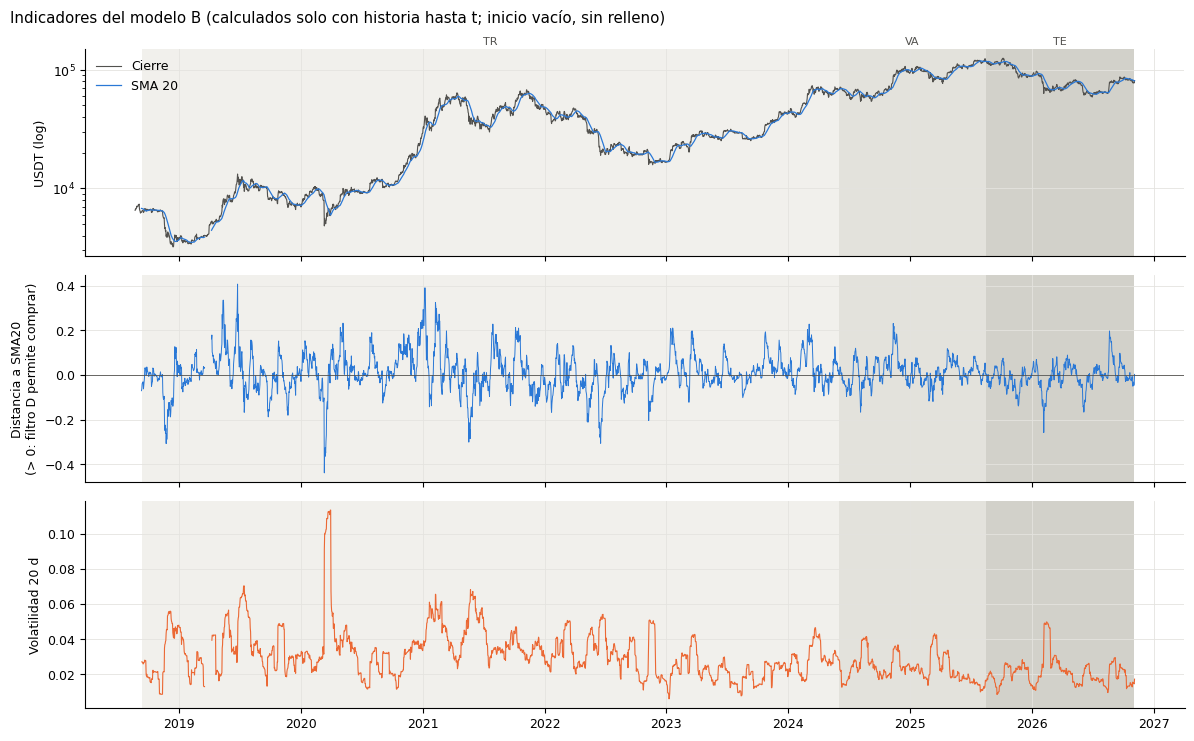

In [18]:
# === 3.1 Gráfica de los dos indicadores del modelo ===
TINTA2, AZUL, NARANJA, GRIS, REJILLA = '#52514e', '#2a78d6', '#eb6834', '#9a9893', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': REJILLA, 'grid.linewidth': 0.6, 'font.size': 9})
TONOS = {'TR': '#f1f0ec', 'VA': '#e3e2dc', 'TE': '#d2d1ca'}
def sombrear(ax, rotular=False):
    for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE)):
        a, b = p.fecha_emision.min(), p.fecha_emision.max()
        ax.axvspan(a, b, color=TONOS[nombre], zorder=0, lw=0)
        if rotular:
            ax.text(a + (b - a) / 2, 1.01, nombre, transform=ax.get_xaxis_transform(), ha='center', va='bottom', color=TINTA2, fontsize=8)
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
sombrear(axes[0], True)
axes[0].plot(DIA.index, DIA['close'], color=TINTA2, lw=0.8, label='Cierre')
axes[0].plot(DIA.index, DIA['sma20'], color=AZUL, lw=0.9, label='SMA 20')
axes[0].set_yscale('log'); axes[0].set_ylabel('USDT (log)'); axes[0].legend(frameon=False, loc='upper left')
sombrear(axes[1])
axes[1].plot(DIA.index, DIA['dist_sma20'], color=AZUL, lw=0.7); axes[1].axhline(0, color=TINTA2, lw=0.6)
axes[1].set_ylabel('Distancia a SMA20\n(> 0: filtro D permite comprar)')
sombrear(axes[2])
axes[2].plot(DIA.index, DIA['vol20'], color=NARANJA, lw=0.8); axes[2].set_ylabel('Volatilidad 20 d')
fig.suptitle('Indicadores del modelo B (calculados solo con historia hasta t; inicio vacío, sin relleno)', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap11_indicadores.png', dpi=150, bbox_inches='tight')
plt.show()

Pares redundantes en TR (|Spearman| ≥ 0.8):
  dist_sma20           ~ bb_pctb              +0.95
  dist_sma20           ~ rsi14                +0.92
  rsi14                ~ bb_pctb              +0.90
  rsi14                ~ suma_20_rezagos      +0.88
  vol20                ~ atr14_pct            +0.86
  dist_sma20           ~ suma_20_rezagos      +0.86

Correlación de los indicadores del modelo entre sí: -0.03
Correlación con el objetivo y_t en TR (Spearman):
dist_sma20           0.004
vol20                0.010
rsi14                0.021
bb_pctb             -0.004
atr14_pct           -0.002
macd_hist_pct       -0.016
ret_t (ret_lag_0)   -0.076
suma_20_rezagos      0.014


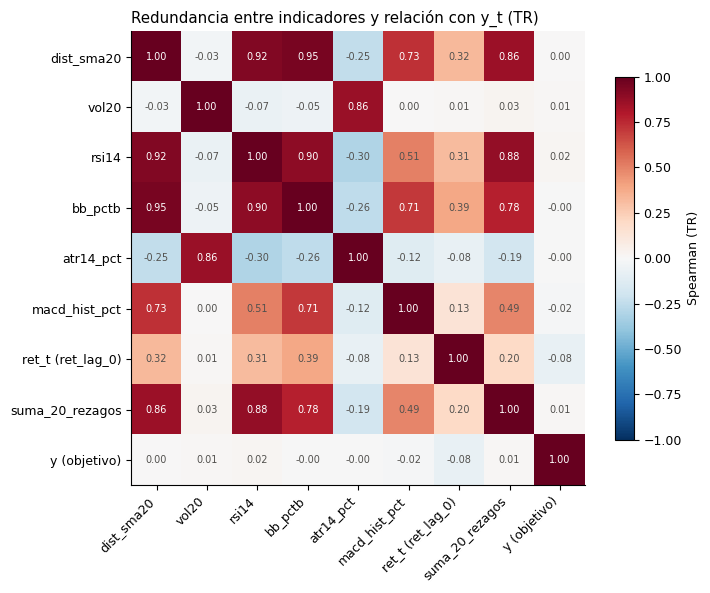

In [19]:
# === 3.2 Redundancia y correlaciones (solo TR) ===
pos_tr = DIA.index.get_indexer(TR['fecha_emision'])
M = pd.DataFrame({c: DIA[c].to_numpy()[pos_tr] for c in IND_TODOS})
M['ret_t (ret_lag_0)'] = TR['ret_lag_0'].to_numpy()
M['suma_20_rezagos'] = TR[FEATS].to_numpy(float).sum(axis=1)
M['y (objetivo)'] = TR['y'].to_numpy()
CORR = M.corr(method='spearman')
CORR.to_csv(DIRS['resultados'] / 'correlaciones_indicadores_TR_cap11.csv')
pares = [(a, b, CORR.loc[a, b]) for i, a in enumerate(CORR.columns) for b in CORR.columns[i + 1:]
         if a != 'y (objetivo)' and b != 'y (objetivo)' and abs(CORR.loc[a, b]) >= 0.8]
print('Pares redundantes en TR (|Spearman| ≥ 0.8):')
for a, b, v in sorted(pares, key=lambda x: -abs(x[2])):
    print(f'  {a:20s} ~ {b:20s} {v:+.2f}')
print(f"\nCorrelación de los indicadores del modelo entre sí: {CORR.loc[IND[0], IND[1]]:+.2f}")
print('Correlación con el objetivo y_t en TR (Spearman):')
print(CORR['y (objetivo)'].drop('y (objetivo)').round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(CORR.to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR)), CORR.columns, rotation=45, ha='right'); ax.set_yticks(range(len(CORR)), CORR.columns)
for i in range(len(CORR)):
    for j in range(len(CORR)):
        ax.text(j, i, f'{CORR.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(CORR.iloc[i, j]) > 0.6 else TINTA2)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label='Spearman (TR)')
ax.set_title('Redundancia entre indicadores y relación con y_t (TR)', loc='left')
fig.tight_layout(); fig.savefig(DIRS['figuras'] / 'cap11_correlaciones.png', dpi=150, bbox_inches='tight'); plt.show()

## 4. Comparación A (rezagos) vs B (rezagos + indicadores) con el mismo protocolo

- **Mismo modelo y mismo protocolo:** misma arquitectura y número de neuronas del Avance 2, las mismas tres semillas, el mismo lote, la misma tasa de aprendizaje, la misma parada temprana con VA y los mismos escaladores ajustados solo con TR.
- **Entradas:**
  - Regresión lineal y MLP A: los 20 rezagos.
  - Regresión lineal y MLP B: los 20 rezagos más `dist_sma20` y `vol20` del día $t$.
  - LSTM A: secuencia de 20 pasos con 1 variable (el rendimiento).
  - LSTM B: secuencia de 20 pasos con 3 variables (rendimiento, `dist_sma20` y `vol20` de **cada** día de la secuencia).
- **Mismas filas:** la LSTM B necesita indicadores válidos en los 20 días de la secuencia, y eso exige más historia al inicio. Por eso **A y B se entrenan con las mismas filas de TR**, las que tienen todo válido, y se evalúan en **exactamente las mismas fechas de VA**. Las primeras filas de TR que se pierden se reportan. Los modelos A se reentrenan con esas filas para que la comparación sea justa; la LSTM original del Avance 2 se muestra como referencia.

In [20]:
# === 4. Matrices A y B ===
from numpy.lib.stride_tricks import sliding_window_view
ARR = DIA[['ret'] + IND].to_numpy(float)
VENT = sliding_window_view(ARR, (N, 1 + len(IND)))[:, 0]           # VENT[j] = días j … j+N−1 (antiguo → reciente)

def secuencia_B(fechas):
    p = DIA.index.get_indexer(pd.DatetimeIndex(fechas))
    if (p < N - 1).any() or (p < 0).any():
        return None, np.zeros(len(p), dtype=bool)
    seq = VENT[p - (N - 1)]
    return seq, np.isfinite(seq).all(axis=(1, 2))

def filas_validas(df):
    'True si la secuencia de 20 días con rendimiento e indicadores está completa (sin vacíos) para esa fecha de emisión.'
    p = DIA.index.get_indexer(df['fecha_emision'])
    ok = np.zeros(len(df), dtype=bool)
    dentro = p >= N - 1
    ok[dentro] = np.isfinite(VENT[p[dentro] - (N - 1)]).all(axis=(1, 2))
    return ok

ok_tr = filas_validas(TR)
TRc = TR.loc[ok_tr].reset_index(drop=True)
for nombre, df in (('VA', VA), ('TE', TE)):
    if not filas_validas(df).all():
        raise DimensionError(f'{nombre} tiene filas sin indicadores válidos: A y B no tendrían las mismas fechas.')
print(f'TR: {len(TR)} filas; con indicadores válidos en toda la secuencia: {len(TRc)} '
      f'(se excluyen {len(TR) - len(TRc)} filas iniciales, hasta {TR.loc[~ok_tr, "fecha_emision"].max().date() if (~ok_tr).any() else "ninguna"})')
print(f'VA y TE: todas las filas válidas ({len(VA)} y {len(TE)}): A y B se evalúan en las mismas fechas.')

def crudos(df):
    lags = df[FEATS].to_numpy(float)
    p = DIA.index.get_indexer(df['fecha_emision'])
    ind_t = DIA[IND].to_numpy(float)[p]
    seq, ok = secuencia_B(df['fecha_emision'])
    if not ok.all():
        raise ValorInvalidoError('Secuencias con indicadores vacíos.')
    if not np.allclose(seq[:, :, 0], lags[:, ::-1], rtol=1e-10):
        raise DimensionError('El canal de rendimientos de la secuencia B no coincide con los rezagos.')
    return lags, ind_t, seq, df['y'].to_numpy(float)

RAW = {'TR': crudos(TRc), 'VA': crudos(VA)}
lags_tr, ind_tr, seq_tr, yc_tr = RAW['TR']
ESC = {'A': StandardScaler().fit(lags_tr), 'B': StandardScaler().fit(np.hstack([lags_tr, ind_tr])),
       'canales': StandardScaler().fit(seq_tr[:, :, 1:].reshape(-1, len(IND))), 'y': StandardScaler().fit(yc_tr.reshape(-1, 1))}
for k, e in ESC.items():
    esperado = len(TRc) * (N if k == 'canales' else 1)
    if e.n_samples_seen_ != esperado:
        raise FugaInformacionError(f'El escalador {k} vio {e.n_samples_seen_} filas; se esperaban {esperado} de TR.')
    joblib.dump(e, DIR_MOD11 / f'escalador_{k}_cap11.joblib')

def entradas(conj):
    lags, ind_t, seq, y = RAW[conj]
    xa = ESC['A'].transform(lags)
    canales = ESC['canales'].transform(seq[:, :, 1:].reshape(-1, len(IND))).reshape(len(seq), N, len(IND))
    return {('lr', 'A'): lags, ('lr', 'B'): np.hstack([lags, ind_t]),
            ('mlp', 'A'): xa.astype('float32'), ('mlp', 'B'): ESC['B'].transform(np.hstack([lags, ind_t])).astype('float32'),
            ('lstm', 'A'): a_secuencia(xa),
            ('lstm', 'B'): np.concatenate([a_secuencia(xa), canales.astype('float32')], axis=2)}, y

X11, Y11 = {}, {}
for conj in ('TR', 'VA'):
    X11[conj], Y11[conj] = entradas(conj)
ys = lambda v: ESC['y'].transform(np.asarray(v).reshape(-1, 1)).ravel()
yinv = lambda v: ESC['y'].inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()
for (m, v), X in X11['TR'].items():
    print(f'{m.upper():4s} {v}: TR {X.shape}  VA {X11["VA"][(m, v)].shape}')

TR: 2067 filas; con indicadores válidos en toda la secuencia: 2029 (se excluyen 38 filas iniciales, hasta 2019-04-28)
VA y TE: todas las filas válidas (442 y 444): A y B se evalúan en las mismas fechas.
LR   A: TR (2029, 20)  VA (442, 20)
LR   B: TR (2029, 22)  VA (442, 22)
MLP  A: TR (2029, 20)  VA (442, 20)
MLP  B: TR (2029, 22)  VA (442, 22)
LSTM A: TR (2029, 20, 1)  VA (442, 20, 1)
LSTM B: TR (2029, 20, 3)  VA (442, 20, 3)


In [21]:
# === 4.1 Rutina de entrenamiento (mismo protocolo del Avance 2) ===
def construir_v(red, neuronas, forma):
    entrada = keras.Input(shape=forma)
    if red == 'mlp':
        x = layers.Dense(neuronas, activation='relu', name='oculta_1')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='oculta_2')(x)
    else:
        x = layers.LSTM(neuronas, name='lstm')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    m = keras.Model(entrada, layers.Dense(1, name='salida')(x), name=red)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=CONFIG['TASA_APRENDIZAJE']), loss=CONFIG['PERDIDA'])
    return m

def entrenar_o_cargar(red, version, semilla):
    run_id = f'cap11_{red}_{version}_n{MEJOR_N[red]}_s{semilla}'
    ckpt, hist_csv, info_json = DIR_MOD11 / f'{run_id}.keras', DIR_MOD11 / f'{run_id}_historia.csv', DIR_MOD11 / f'{run_id}_info.json'
    Xtr, Xva = X11['TR'][(red, version)], X11['VA'][(red, version)]
    forma = (None,) + Xtr.shape[1:]
    verificar_formas(f'{run_id} TR', Xtr, Y11['TR'], forma)
    verificar_formas(f'{run_id} VA', Xva, Y11['VA'], forma)
    if not CONFIG['REENTRENAR_CAP11'] and ckpt.exists() and hist_csv.exists() and info_json.exists():
        modelo = keras.models.load_model(ckpt)
        return run_id, modelo, pd.read_csv(hist_csv), {**json.load(open(info_json)), 'origen': 'cargado de Drive'}
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    lote = CONFIG['LOTE']
    for intento in range(3):
        cbs = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=CONFIG['PACIENCIA'], restore_best_weights=True),
               keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True),
               keras.callbacks.CSVLogger(str(hist_csv)), keras.callbacks.TerminateOnNaN()]
        try:
            with tf.device(DISPOSITIVO):
                modelo = construir_v(red, MEJOR_N[red], Xtr.shape[1:])
                t0 = time.perf_counter()
                h = modelo.fit(Xtr, ys(Y11['TR']), validation_data=(Xva, ys(Y11['VA'])), epochs=CONFIG['MAX_EPOCAS'],
                               batch_size=lote, shuffle=True, callbacks=cbs, verbose=0)
                tiempo = time.perf_counter() - t0
            break
        except tf.errors.ResourceExhaustedError as e:
            registrar_evento('cap11 entrenamiento', 'Memoria insuficiente (OOM)', f'{run_id} lote {lote}', f'lote → {lote // 2}', 'reintento')
            lote //= 2
            if lote < 4:
                raise EntrenamientoError(f'{run_id}: sin memoria.') from e
    hist = pd.DataFrame(h.history)
    if not np.isfinite(hist[['loss', 'val_loss']].to_numpy()).all():
        registrar_evento('cap11 entrenamiento', 'Pérdida no finita', run_id, 'Entrenamiento detenido', 'pendiente')
        raise EntrenamientoError(f'{run_id}: pérdida no finita.')
    va_rest = float(modelo.evaluate(Xva, ys(Y11['VA']), verbose=0, batch_size=1024))
    if not np.isclose(va_rest, hist['val_loss'].min(), rtol=1e-3, atol=1e-6):
        modelo = keras.models.load_model(ckpt)
    disp = dispositivo_de(modelo.trainable_variables[0])
    if CONFIG['REQUIERE_T4'] and 'GPU' not in disp.upper():
        raise EntrenamientoError(f'{run_id}: los pesos quedaron en {disp}, no en la GPU.')
    info = {'epocas': len(hist), 'mejor_epoca': int(hist['val_loss'].to_numpy().argmin()) + 1, 'tiempo_s': round(tiempo, 2),
            'dispositivo_pesos': disp, 'gpu': GPU_NOMBRE, 'lote': lote,
            'params_entrenables': int(sum(np.prod(v.shape) for v in modelo.trainable_variables)), 'capas': describir_capas(modelo)}
    json.dump(info, open(info_json, 'w'), indent=2)
    return run_id, modelo, hist, {**info, 'origen': 'entrenado ahora'}

In [22]:
# === 4.2 Entrenamiento A y B (3 semillas cada uno) y regresión lineal A y B ===
MOD11, PRED11, INFO11, HIST11, FILAS11 = {}, {}, [], {}, []
for red in ('lstm', 'mlp'):
    for v in ('A', 'B'):
        MOD11[(red, v)] = []
        for s in SEMILLAS:
            rid, m, h, info = entrenar_o_cargar(red, v, s)
            MOD11[(red, v)].append(m)
            HIST11[rid] = h
            pr = {c: yinv(predecir(m, X11[c][(red, v)], c)) for c in ('TR', 'VA')}
            INFO11.append({'id': rid, 'red': red, 'version': v, 'semilla': s, **info,
                           'RMSE_TR': metricas(Y11['TR'], pr['TR'])['RMSE'], 'RMSE_VA': metricas(Y11['VA'], pr['VA'])['RMSE'],
                           'MAE_VA': metricas(Y11['VA'], pr['VA'])['MAE']})
            print(f"{rid:26s} {info['dispositivo_pesos'][-12:]:>12s} | {info['origen']:16s} | épocas {info['epocas']:3d} "
                  f"(mejor {info['mejor_epoca']:3d}) | RMSE VA {INFO11[-1]['RMSE_VA']:.6f}")
        PRED11[(red, v)] = {c: yinv(predecir(MOD11[(red, v)], X11[c][(red, v)], c)) for c in ('TR', 'VA')}
LR11 = {}
for v in ('A', 'B'):
    LR11[v] = LinearRegression().fit(X11['TR'][('lr', v)], Y11['TR'])
    PRED11[('lr', v)] = {c: predecir(LR11[v], X11[c][('lr', v)], c) for c in ('TR', 'VA')}
    joblib.dump(LR11[v], DIR_MOD11 / f'regresion_lineal_{v}_cap11.joblib')
INFO11 = pd.DataFrame(INFO11)
INFO11.to_csv(DIRS['resultados'] / 'entrenamientos_cap11.csv', index=False)

ahora = datetime.now(timezone.utc).isoformat(timespec='seconds')
filas_exp = []
for (m, v), p in PRED11.items():
    for conj in ('TR', 'VA'):
        df_c = TRc if conj == 'TR' else VA
        filas_exp.append({'id': f'cap11_{m}_{v}' + ('_ensamble3' if m != 'lr' else ''), 'capitulo': 11,
                          'modelo': f'{m}_{v}', 'tipo': 'comparacion_indicadores',
                          'variables': f'{N} rezagos' + (f' + {", ".join(IND)}' if v == 'B' else ''),
                          'semilla': '/'.join(map(str, SEMILLAS)) if m != 'lr' else '', 'dispositivo': DISPOSITIVO if m != 'lr' else 'CPU',
                          'conjunto': conj, 'primer_objetivo': df_c.fecha_objetivo.min().date(), 'ultimo_objetivo': df_c.fecha_objetivo.max().date(),
                          **metricas(Y11[conj], p[conj]), 'tf_version': tf.__version__, 'fecha_ejecucion_utc': ahora})
registrar_experimentos(filas_exp)
print('\nRegistrado en experimentos.csv (capítulo 11).')

cap11_lstm_A_n20_s42       device:GPU:0 | cargado de Drive | épocas  26 (mejor   1) | RMSE VA 0.024327
cap11_lstm_A_n20_s123      device:GPU:0 | cargado de Drive | épocas  26 (mejor   1) | RMSE VA 0.024289
cap11_lstm_A_n20_s2024     device:GPU:0 | cargado de Drive | épocas  26 (mejor   1) | RMSE VA 0.024314
cap11_lstm_B_n20_s42       device:GPU:0 | cargado de Drive | épocas  26 (mejor   1) | RMSE VA 0.024413
cap11_lstm_B_n20_s123      device:GPU:0 | cargado de Drive | épocas  26 (mejor   1) | RMSE VA 0.024389
cap11_lstm_B_n20_s2024     device:GPU:0 | cargado de Drive | épocas  33 (mejor   8) | RMSE VA 0.024304
cap11_mlp_A_n10_s42        device:GPU:0 | cargado de Drive | épocas  45 (mejor  20) | RMSE VA 0.024309
cap11_mlp_A_n10_s123       device:GPU:0 | cargado de Drive | épocas  34 (mejor   9) | RMSE VA 0.024579
cap11_mlp_A_n10_s2024      device:GPU:0 | cargado de Drive | épocas  48 (mejor  23) | RMSE VA 0.024495
cap11_mlp_B_n10_s42        device:GPU:0 | cargado de Drive | épocas  38 (

In [23]:
# === 4.3 A vs B en las mismas fechas de VA ===
filas_cmp = []
for m in ('lr', 'mlp', 'lstm'):
    for v in ('A', 'B'):
        mv = metricas(Y11['VA'], PRED11[(m, v)]['VA'])
        sem = INFO11[(INFO11.red == m) & (INFO11.version == v)]
        filas_cmp.append({'modelo': m, 'version': v, 'RMSE_VA': mv['RMSE'], 'MAE_VA': mv['MAE'],
                          'prec_dir_VA': mv['prec_direccional'], 'RMSE_TR': metricas(Y11['TR'], PRED11[(m, v)]['TR'])['RMSE'],
                          'RMSE_VA_media_semillas': sem['RMSE_VA'].mean() if len(sem) else np.nan,
                          'RMSE_VA_std_semillas': sem['RMSE_VA'].std(ddof=1) if len(sem) else np.nan})
CMP = pd.DataFrame(filas_cmp)
ref = metricas(y_va, PRED8[RED_PRINCIPAL]['VA'])
print(f"Referencia: {RED_PRINCIPAL.upper()} original del Avance 2 (todas las filas de TR): RMSE VA {ref['RMSE']:.6f}, MAE VA {ref['MAE']:.6f}")
print(f"Pronóstico cero en VA: RMSE {REF_VA.loc['cero', 'RMSE']:.6f}, MAE {REF_VA.loc['cero', 'MAE']:.6f}\n")

AB = []
for m in ('lr', 'mlp', 'lstm'):
    a, b = CMP[(CMP.modelo == m) & (CMP.version == 'A')].iloc[0], CMP[(CMP.modelo == m) & (CMP.version == 'B')].iloc[0]
    d_rmse, d_mae = 100 * (b.RMSE_VA / a.RMSE_VA - 1), 100 * (b.MAE_VA / a.MAE_VA - 1)
    ruido = b.RMSE_VA_std_semillas if np.isfinite(b.RMSE_VA_std_semillas) else 0.0
    supera_ruido = (a.RMSE_VA - b.RMSE_VA) > ruido
    AB.append({'modelo': m, 'RMSE_VA_A': a.RMSE_VA, 'RMSE_VA_B': b.RMSE_VA, 'cambio_RMSE_%': d_rmse,
               'MAE_VA_A': a.MAE_VA, 'MAE_VA_B': b.MAE_VA, 'cambio_MAE_%': d_mae,
               'RMSE': 'mejora' if d_rmse < 0 else 'empeora', 'MAE': 'mejora' if d_mae < 0 else 'empeora',
               'desv_semillas_B': ruido if m != 'lr' else np.nan, 'mejora_mayor_que_ruido': bool(supera_ruido)})
AB = pd.DataFrame(AB)
AB.to_csv(DIRS['resultados'] / 'comparacion_A_vs_B_VA_cap11.csv', index=False)
CMP.to_csv(DIRS['resultados'] / 'versiones_A_B_cap11.csv', index=False)
AB.round(6)

Referencia: LSTM original del Avance 2 (todas las filas de TR): RMSE VA 0.024286, MAE VA 0.017242
Pronóstico cero en VA: RMSE 0.024342, MAE 0.017219



,modelo,RMSE_VA_A,RMSE_VA_B,cambio_RMSE_%,MAE_VA_A,MAE_VA_B,cambio_MAE_%,RMSE,MAE,desv_semillas_B,mejora_mayor_que_ruido
0,lr,0.024242,0.024213,-0.123485,0.017271,0.017212,-0.343301,mejora,mejora,NaN,True
1,mlp,0.024260,0.024311,0.210224,0.017264,0.017341,0.449939,empeora,empeora,0.000169,False
2,lstm,0.024306,0.024352,0.188393,0.017243,0.017297,0.312153,empeora,empeora,0.000057,False


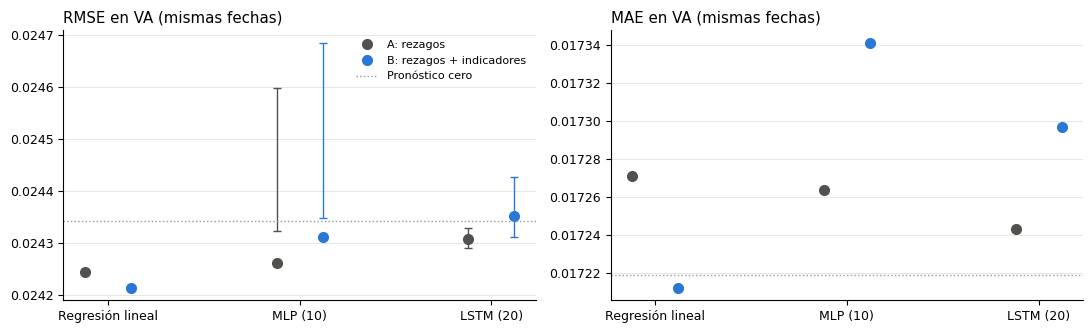

In [24]:
# === 4.3.1 Gráfica A vs B ===
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, met in zip(axes, ('RMSE_VA', 'MAE_VA')):
    for i, m in enumerate(('lr', 'mlp', 'lstm')):
        for v, color, dx in (('A', TINTA2, -0.12), ('B', AZUL, 0.12)):
            fila = CMP[(CMP.modelo == m) & (CMP.version == v)].iloc[0]
            ax.plot(i + dx, fila[met], 'o', color=color, ms=7, label=('A: rezagos' if v == 'A' else 'B: rezagos + indicadores') if i == 0 else None)
            if met == 'RMSE_VA' and np.isfinite(fila['RMSE_VA_std_semillas']):
                ax.errorbar(i + dx, fila['RMSE_VA_media_semillas'], yerr=fila['RMSE_VA_std_semillas'], fmt='none', ecolor=color, capsize=3, lw=1)
    ref_val = REF_VA.loc['cero', 'RMSE' if met == 'RMSE_VA' else 'MAE']
    ax.axhline(ref_val, color=GRIS, ls=':', lw=1, label='Pronóstico cero')
    ax.set_xticks(range(3), ['Regresión lineal', f"MLP ({MEJOR_N['mlp']})", f"LSTM ({MEJOR_N['lstm']})"])
    ax.set_title(f"{met.replace('_VA', '')} en VA (mismas fechas)", loc='left'); ax.grid(axis='x', visible=False)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DIRS['figuras'] / 'cap11_A_vs_B.png', dpi=150, bbox_inches='tight'); plt.show()

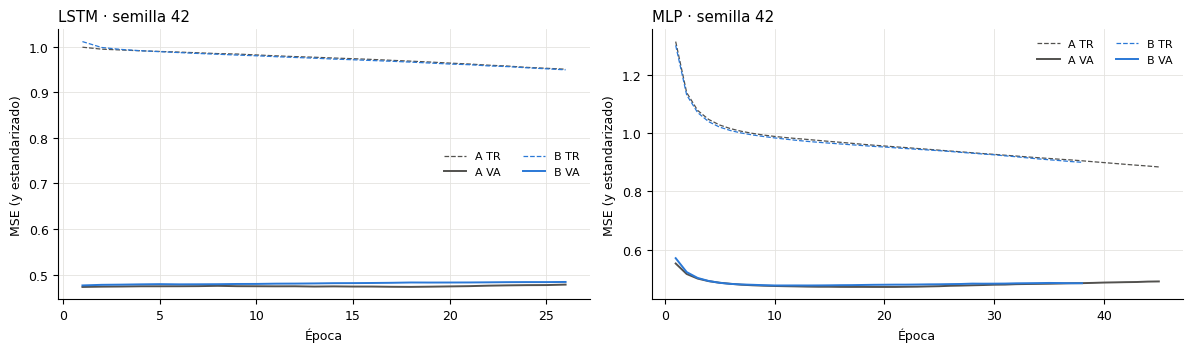

Criterio: casi constante si desv(predicción) / desv(real) < 0.05 en VA.
Causas posibles según el capítulo 11: arquitectura poco expresiva, datos ruidosos, pérdida inadecuada o hiperparámetros.
Con rendimientos diarios, el MSE se minimiza acercándose a la media, así que una predicción casi constante es esperable
cuando las variables tienen poca información.
              mejor_epoca  epocas
red  version                     
lstm A                1.0    26.0
     B                3.3    28.3
mlp  A               17.3    42.3
     B               14.0    39.0


,modelo,desv_pred_VA,desv_real_VA,cociente,fraccion_positivas,rango_pred,casi_constante
0,lstm_A,0.00058,0.02429,0.02378,1.00000,+0.0165% a +0.4313%,True
1,lstm_B,0.00181,0.02429,0.07458,0.69683,-0.3069% a +0.5653%,False
2,mlp_A,0.00240,0.02429,0.09868,0.71267,-0.7210% a +1.0818%,False
3,mlp_B,0.00283,0.02429,0.11651,0.71267,-1.1641% a +1.3164%,False
4,lr_A,0.00301,0.02429,0.12403,0.74661,-1.1975% a +1.3458%,False
5,lr_B,0.00306,0.02429,0.12590,0.63348,-1.2382% a +1.3157%,False


In [25]:
# === 4.4 Diagnóstico del entrenamiento y predicciones casi constantes ===
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, red in zip(axes, ('lstm', 'mlp')):
    for v, color in (('A', TINTA2), ('B', AZUL)):
        h = HIST11[f'cap11_{red}_{v}_n{MEJOR_N[red]}_s{SEMILLAS[0]}']
        ep = np.arange(1, len(h) + 1)
        ax.plot(ep, h['loss'], color=color, lw=0.9, ls='--', label=f'{v} TR')
        ax.plot(ep, h['val_loss'], color=color, lw=1.4, label=f'{v} VA')
    ax.set_title(f'{red.upper()} · semilla {SEMILLAS[0]}', loc='left'); ax.set_xlabel('Época'); ax.set_ylabel('MSE (y estandarizado)')
    ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(DIRS['figuras'] / 'cap11_curvas_A_B.png', dpi=150, bbox_inches='tight'); plt.show()

sd_real = np.std(Y11['VA'])
CONST = []
for (m, v), p in PRED11.items():
    pv = p['VA']
    ratio = np.std(pv) / sd_real
    CONST.append({'modelo': f'{m}_{v}', 'desv_pred_VA': np.std(pv), 'desv_real_VA': sd_real, 'cociente': ratio,
                  'fraccion_positivas': np.mean(pv > 0), 'rango_pred': f'{pv.min():+.4%} a {pv.max():+.4%}',
                  'casi_constante': ratio < CONFIG['UMBRAL_CASI_CONSTANTE']})
CONST = pd.DataFrame(CONST)
CONST.to_csv(DIRS['resultados'] / 'predicciones_casi_constantes_cap11.csv', index=False)
print(f"Criterio: casi constante si desv(predicción) / desv(real) < {CONFIG['UMBRAL_CASI_CONSTANTE']} en VA.")
print('Causas posibles según el capítulo 11: arquitectura poco expresiva, datos ruidosos, pérdida inadecuada o hiperparámetros.')
print('Con rendimientos diarios, el MSE se minimiza acercándose a la media, así que una predicción casi constante es esperable')
print('cuando las variables tienen poca información.')
diag = INFO11.groupby(['red', 'version'])[['mejor_epoca', 'epocas']].mean().round(1)
display(diag) if 'display' in globals() else print(diag)
CONST.round(5)

In [26]:
# === 4.5 Versión seleccionada con VA para cada modelo ===
VERSION = {}
for _, r in AB.iterrows():
    if r['modelo'] == 'lr':
        VERSION['lr'] = 'B' if r['RMSE_VA_B'] < r['RMSE_VA_A'] else 'A'
    else:
        VERSION[r['modelo']] = 'B' if r['mejora_mayor_que_ruido'] else 'A'
for m, v in VERSION.items():
    print(f"{m.upper():4s} → versión {v}" + ('' if m == 'lr' else
          ('  (B mejora el RMSE de VA más que la variación entre semillas)' if v == 'B'
           else '  (B no mejora más que la variación entre semillas: se conserva la versión sencilla)')))
FINAL = (RED_PRINCIPAL, VERSION[RED_PRINCIPAL])
print(f"\nModelo de pronóstico del sistema final: {RED_PRINCIPAL.upper()} versión {FINAL[1]} (ensamble de {len(SEMILLAS)} semillas)")

LR   → versión B
MLP  → versión A  (B no mejora más que la variación entre semillas: se conserva la versión sencilla)
LSTM → versión A  (B no mejora más que la variación entre semillas: se conserva la versión sencilla)

Modelo de pronóstico del sistema final: LSTM versión A (ensamble de 3 semillas)


## 5. Estrategia C (solo pronóstico) vs D (pronóstico + filtro SMA20) en VA

- **C:** comprar, o mantener comprado, si $\hat y_t > \delta$; si no, efectivo.
- **D:** comprar, o mantener comprado, si $\hat y_t > \delta$ **y** $C_t > \text{SMA}_{20,t}$; si no, efectivo o cerrar la posición. Es la regla de confirmación obligatoria del protocolo.
- δ se elige entre **hasta cinco valores positivos predefinidos**: cuantiles 10–90 % de las predicciones del modelo final en TR, registrados antes de simular VA. Se elige por mayor rendimiento neto en VA y, en empate, por menor drawdown. Se elige por separado para C y para D.
- Un filtro **cambia operaciones, no predicciones**: no cambia MAE ni RMSE.
- Se elige entre C y D con el mismo criterio. Como referencias se incluyen la regresión lineal con su propio δ, comprar y mantener, y efectivo.

In [27]:
# === 5. C vs D en VA ===
P_FINAL = PRED11[FINAL]
P_LR = PRED11[('lr', VERSION['lr'])]
FILTRO = {c: (DIA['dist_sma20'].to_numpy()[DIA.index.get_indexer(df['fecha_emision'])] > 0) for c, df in (('TR', TRc), ('VA', VA))}

def candidatos(p_tr):
    q = np.quantile(p_tr, CONFIG['CUANTILES_UMBRAL'])
    pos_ = sorted({round(float(v), 6) for v in q if v > 0})
    return (pos_ or list(CONFIG['UMBRALES_RESPALDO']))[:5]
CAND = {'final': candidatos(P_FINAL['TR']), 'lr': candidatos(P_LR['TR'])}
json.dump({**CAND, 'origen': 'cuantiles de las predicciones en TR', 'fecha_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')},
          open(DIRS['resultados'] / 'umbrales_candidatos_cap11.json', 'w'), indent=2)

FECHAS_VA = VA['fecha_objetivo']
filas_s, SIMS_VA = [], {}
for estrategia, pred, cand, filtro in (('C', P_FINAL['VA'], CAND['final'], False), ('D', P_FINAL['VA'], CAND['final'], True),
                                        ('LR', P_LR['VA'], CAND['lr'], False)):
    for d in cand:
        senal = (pred > d) & (FILTRO['VA'] if filtro else True)
        res, sim = simular(FECHAS_VA, senal.astype(int))
        SIMS_VA[(estrategia, d)] = sim
        filas_s.append({'estrategia': estrategia, 'delta': d, **res})
EST_VA = pd.DataFrame(filas_s)
BH_VA, SIM_BH_VA = simular(FECHAS_VA, np.ones(len(VA), int))

def elegir(df):
    df = df.assign(_r=df['rendimiento_neto'].round(8))
    return df.sort_values(['_r', 'max_drawdown'], ascending=[False, False]).iloc[0]
ELEC = {e: elegir(EST_VA[EST_VA.estrategia == e]) for e in ('C', 'D', 'LR')}
ESTRATEGIA_FINAL = 'D' if (round(ELEC['D']['rendimiento_neto'], 8), ELEC['D']['max_drawdown']) > \
                          (round(ELEC['C']['rendimiento_neto'], 8), ELEC['C']['max_drawdown']) else 'C'
EST_VA.to_csv(DIRS['resultados'] / 'umbrales_C_D_VA_cap11.csv', index=False)

resumen_cd = pd.DataFrame([{'estrategia': f"{e} (δ = {ELEC[e]['delta']:.4%})", 'rendimiento_neto': ELEC[e]['rendimiento_neto'],
                            'max_drawdown': ELEC[e]['max_drawdown'], 'operaciones_cerradas': int(ELEC[e]['operaciones_cerradas']),
                            'dias_en_mercado_%': ELEC[e]['dias_en_mercado_%'], 'win_rate': ELEC[e]['win_rate'],
                            'costos_totales': ELEC[e]['costos_totales']} for e in ('C', 'D', 'LR')] +
                          [{'estrategia': 'Comprar y mantener', 'rendimiento_neto': BH_VA['rendimiento_neto'], 'max_drawdown': BH_VA['max_drawdown'],
                            'operaciones_cerradas': 1, 'dias_en_mercado_%': 100.0, 'win_rate': BH_VA['win_rate'], 'costos_totales': BH_VA['costos_totales']},
                           {'estrategia': 'Efectivo', 'rendimiento_neto': 0.0, 'max_drawdown': 0.0, 'operaciones_cerradas': 0,
                            'dias_en_mercado_%': 0.0, 'win_rate': np.nan, 'costos_totales': 0.0}])
resumen_cd.to_csv(DIRS['resultados'] / 'comparacion_C_D_VA_cap11.csv', index=False)
print(f"Estrategia elegida con VA: {ESTRATEGIA_FINAL} (δ = {ELEC[ESTRATEGIA_FINAL]['delta']:.4%})")
print(f"  C: {ELEC['C']['rendimiento_neto']:+.2%} | D: {ELEC['D']['rendimiento_neto']:+.2%} | "
      f"comprar y mantener: {BH_VA['rendimiento_neto']:+.2%}")
v = resumen_cd.copy()
for c in ('rendimiento_neto', 'max_drawdown', 'win_rate'):
    v[c] = v[c].map(lambda x: '' if pd.isna(x) else f'{x:+.2%}')
v['costos_totales'] = resumen_cd['costos_totales'].round(2); v['dias_en_mercado_%'] = resumen_cd['dias_en_mercado_%'].round(1)
v

Estrategia elegida con VA: D (δ = 0.0866%)
  C: +47.54% | D: +51.17% | comprar y mantener: +72.91%


,estrategia,rendimiento_neto,max_drawdown,operaciones_cerradas,dias_en_mercado_%,win_rate,costos_totales
0,C (δ = 0.0866%),+47.54%,-43.31%,24,88.5,+41.67%,5715.39
1,D (δ = 0.0866%),+51.17%,-26.29%,20,55.7,+35.00%,5223.55
2,LR (δ = 0.1233%),+28.00%,-20.29%,107,42.8,+49.53%,22683.06
3,Comprar y mantener,+72.91%,-28.10%,1,100.0,+100.00%,272.98
4,Efectivo,+0.00%,+0.00%,0,0.0,,0.00


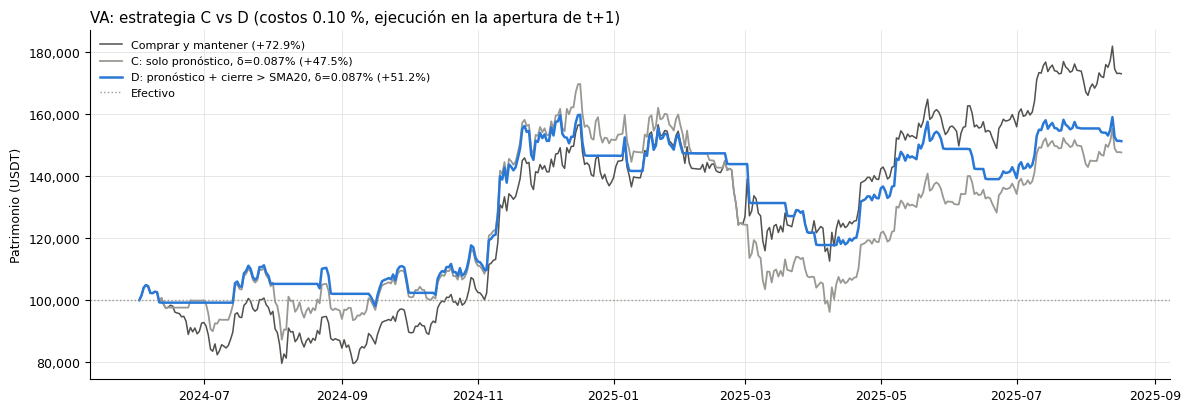

In [28]:
# === 5.1 Patrimonio en VA: C vs D ===
def curva(sim):
    s = sim.groupby('fecha')['patrimonio'].last()
    return pd.to_datetime(s.index), s.to_numpy()
fig, ax = plt.subplots(figsize=(12, 4.2))
for etiqueta, sim, color, lw in ((f"Comprar y mantener ({BH_VA['rendimiento_neto']:+.1%})", SIM_BH_VA, TINTA2, 1.1),
                                 (f"C: solo pronóstico, δ={ELEC['C']['delta']:.3%} ({ELEC['C']['rendimiento_neto']:+.1%})", SIMS_VA[('C', ELEC['C']['delta'])], GRIS, 1.3),
                                 (f"D: pronóstico + cierre > SMA20, δ={ELEC['D']['delta']:.3%} ({ELEC['D']['rendimiento_neto']:+.1%})", SIMS_VA[('D', ELEC['D']['delta'])], AZUL, 1.8)):
    x, y = curva(sim); ax.plot(x, y, color=color, lw=lw, label=etiqueta)
ax.axhline(CONFIG['CAPITAL_INICIAL'], color=GRIS, ls=':', lw=1, label='Efectivo')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}')); ax.set_ylabel('Patrimonio (USDT)')
ax.set_title('VA: estrategia C vs D (costos 0.10 %, ejecución en la apertura de t+1)', loc='left'); ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig(DIRS['figuras'] / 'cap11_C_vs_D_VA.png', dpi=150, bbox_inches='tight'); plt.show()

## 6. Congelar la configuración final (antes de mirar TE)

Todo lo que se evalúa en TE queda fijado aquí: el modelo, la versión, las semillas, los escaladores, δ, el filtro y la estrategia, junto con la lista de versiones que se van a reportar. Se guarda con una huella SHA-256. Si después de evaluar TE la configuración cambiara, el notebook **se detiene**. Así se garantiza que TE se usa **una sola vez** y nunca para elegir.

In [29]:
# === 6. Configuración final congelada ===
CONFIG_FINAL = {
    'modelo_pronostico': f'{FINAL[0]}_{FINAL[1]}', 'neuronas': MEJOR_N[FINAL[0]], 'semillas': SEMILLAS,
    'variables': FEATS + (IND if FINAL[1] == 'B' else []),
    'checkpoints': [f'modelos/cap11/cap11_{FINAL[0]}_{FINAL[1]}_n{MEJOR_N[FINAL[0]]}_s{s}.keras' for s in SEMILLAS],
    'escaladores': ['modelos/cap11/escalador_A_cap11.joblib', 'modelos/cap11/escalador_B_cap11.joblib',
                    'modelos/cap11/escalador_canales_cap11.joblib', 'modelos/cap11/escalador_y_cap11.joblib'],
    'estrategia': ESTRATEGIA_FINAL, 'delta': float(ELEC[ESTRATEGIA_FINAL]['delta']),
    'filtro': 'cierre > SMA20' if ESTRATEGIA_FINAL == 'D' else 'ninguno',
    'versiones_reportadas_en_TE': {
        'pronostico': ['cero', f"regresion_lineal_{VERSION['lr']}", f"mlp_{VERSION['mlp']}", f"lstm_{VERSION['lstm']}"],
        'estrategias': {'C': float(ELEC['C']['delta']), 'D': float(ELEC['D']['delta']), 'LR': float(ELEC['LR']['delta']),
                        'comprar_y_mantener': None, 'efectivo': None}},
    'criterios': 'versiones A/B por RMSE de VA (regla del ruido entre semillas); δ por rendimiento neto en VA (empate: drawdown); C/D por el mismo criterio',
    'costo': CONFIG['COSTO'], 'capital_inicial': CONFIG['CAPITAL_INICIAL'],
}
HUELLA = hashlib.sha256(json.dumps(CONFIG_FINAL, sort_keys=True, default=str).encode()).hexdigest()
json.dump({**CONFIG_FINAL, 'sha256': HUELLA, 'congelado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')},
          open(DIRS['resultados'] / 'configuracion_final_congelada.json', 'w'), indent=2, ensure_ascii=False)
RUTA_LOG_TE = DIRS['resultados'] / 'evaluacion_TE_registro.json'
if RUTA_LOG_TE.exists():
    LOG_TE = json.load(open(RUTA_LOG_TE))
    if LOG_TE['sha256_configuracion'] != HUELLA:
        registrar_evento('evaluación TE', 'Configuración cambió después de ver TE', f"antes {LOG_TE['sha256_configuracion'][:12]}, ahora {HUELLA[:12]}",
                         'Detenido: TE ya se usó; no se puede reelegir. Restaurar la configuración o declarar contaminación.', 'pendiente')
        raise FugaInformacionError('La configuración final cambió después de evaluar TE. TE ya no es independiente: '
                                   'restauren la configuración congelada o declaren la contaminación y usen datos nuevos.')
    print(f"TE ya se evaluó el {LOG_TE['fecha_utc']} con esta misma configuración (SHA {HUELLA[:12]}…): se reproduce, no se reelige.")
else:
    LOG_TE = None
    print(f'Configuración congelada (SHA-256 {HUELLA[:16]}…). TE se evaluará por primera vez.')
CONGELADO = True
pd.Series({k: (v if not isinstance(v, (list, dict)) else json.dumps(v, ensure_ascii=False)[:120]) for k, v in CONFIG_FINAL.items()})

TE ya se evaluó el 2026-11-12T13:50:44+00:00 con esta misma configuración (SHA 97f125d05154…): se reproduce, no se reelige.


,0
modelo_pronostico,lstm_A
neuronas,20
semillas,"[42, 123, 2024]"
variables,"[""ret_lag_0"", ""ret_lag_1"", ""ret_lag_2"", ""ret_lag_3"", ""ret_lag_4"", ""ret_lag_5"", ""ret_lag_6"", ""ret_lag_7"", ""ret_lag_8""..."
checkpoints,"[""modelos/cap11/cap11_lstm_A_n20_s42.keras"", ""modelos/cap11/cap11_lstm_A_n20_s123.keras"", ""modelos/cap11/cap11_lstm_..."
escaladores,"[""modelos/cap11/escalador_A_cap11.joblib"", ""modelos/cap11/escalador_B_cap11.joblib"", ""modelos/cap11/escalador_canale..."
estrategia,D
delta,0.000866
filtro,cierre > SMA20
versiones_reportadas_en_TE,"{""pronostico"": [""cero"", ""regresion_lineal_B"", ""mlp_A"", ""lstm_A""], ""estrategias"": {""C"": 0.000866, ""D"": 0.000866, ""LR""..."


## 7. Evaluación de TE (una sola vez) y resultados finales

In [30]:
# === 7. Predicciones de TE y métricas en TR, VA y TE ===
RAW['TE'] = crudos(TE)
X11['TE'], Y11['TE'] = entradas('TE')
for (m, v) in [('lr', VERSION['lr']), ('mlp', VERSION['mlp']), ('lstm', VERSION['lstm'])]:
    modelo = LR11[v] if m == 'lr' else MOD11[(m, v)]
    PRED11[(m, v)]['TE'] = predecir(modelo, X11['TE'][(m, v)], 'TE') if m == 'lr' else yinv(predecir(modelo, X11['TE'][(m, v)], 'TE'))
P_FINAL, P_LR = PRED11[FINAL], PRED11[('lr', VERSION['lr'])]

filas_res = []
for nombre, clave in [('cero', None), (f"regresion_lineal_{VERSION['lr']}", ('lr', VERSION['lr'])),
                      (f"mlp_{VERSION['mlp']}", ('mlp', VERSION['mlp'])), (f"lstm_{VERSION['lstm']}", ('lstm', VERSION['lstm']))]:
    for conj in ('TR', 'VA', 'TE'):
        p = np.zeros(len(Y11[conj])) if clave is None else PRED11[clave][conj]
        filas_res.append({'modelo': nombre, 'conjunto': conj, **metricas(Y11[conj], p)})
filas_res += [{'modelo': 'comprar_y_mantener', 'conjunto': c, 'MAE': 'no aplica', 'RMSE': 'no aplica', 'prec_direccional': 'no aplica'}
              for c in ('TR', 'VA', 'TE')]
RES = pd.DataFrame(filas_res)
RES.to_csv(DIRS['resultados'] / 'resultados_finales_TR_VA_TE.csv', index=False)
registrar_experimentos([{'id': f"cap11_final_{r['modelo']}", 'capitulo': 11, 'modelo': r['modelo'], 'tipo': 'evaluacion_final',
                         'conjunto': r['conjunto'], **{k: r[k] for k in ('MAE', 'RMSE', 'prec_direccional', 'n')},
                         'semilla': '/'.join(map(str, SEMILLAS)), 'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')}
                        for r in filas_res if r['modelo'] != 'comprar_y_mantener'])

FILTRO['TE'] = DIA['dist_sma20'].to_numpy()[DIA.index.get_indexer(TE['fecha_emision'])] > 0
delta_f = CONFIG_FINAL['delta']
SENAL_TE = (P_FINAL['TE'] > delta_f) & (FILTRO['TE'] if ESTRATEGIA_FINAL == 'D' else True)
PRED_TE = pd.DataFrame({'fecha_emision': TE['fecha_emision'].dt.date, 'fecha_objetivo': TE['fecha_objetivo'].dt.date,
                        'rendimiento_real': Y11['TE'], 'rendimiento_estimado': P_FINAL['TE'],
                        'error': P_FINAL['TE'] - Y11['TE'], 'senal': np.where(SENAL_TE, 'comprar', 'efectivo'),
                        'estimado_regresion_lineal': P_LR['TE'], 'cierre_sobre_SMA20': FILTRO['TE']})
PRED_TE.to_csv(DIRS['resultados'] / 'predicciones_TE.csv', index=False)
tabla = RES.pivot(index='modelo', columns='conjunto', values='RMSE')[['TR', 'VA', 'TE']]
print('RMSE por conjunto (configuraciones finales):'); display(tabla) if 'display' in globals() else print(tabla)
print('MAE por conjunto:')
print(RES.pivot(index='modelo', columns='conjunto', values='MAE')[['TR', 'VA', 'TE']].to_string())
print('Precisión direccional por conjunto:')
print(RES.pivot(index='modelo', columns='conjunto', values='prec_direccional')[['TR', 'VA', 'TE']].to_string())
PRED_TE.head()

RMSE por conjunto (configuraciones finales):
conjunto                   TR         VA         TE
modelo                                             
cero                  0.03541   0.024342   0.022297
comprar_y_mantener  no aplica  no aplica  no aplica
lstm_A               0.035286   0.024306   0.022319
mlp_A                0.034309    0.02426   0.022448
regresion_lineal_B   0.035093   0.024213   0.022362
MAE por conjunto:
conjunto                   TR         VA         TE
modelo                                             
cero                 0.023579   0.017219   0.015632
comprar_y_mantener  no aplica  no aplica  no aplica
lstm_A                0.02355   0.017243   0.015727
mlp_A                0.022949   0.017264   0.015773
regresion_lineal_B   0.023491   0.017212   0.015787
Precisión direccional por conjunto:
conjunto                   TR         VA         TE
modelo                                             
cero                      NaN        NaN        NaN
comprar_y_mantene

,fecha_emision,fecha_objetivo,rendimiento_real,rendimiento_estimado,error,senal,estimado_regresion_lineal,cierre_sobre_SMA20
0,2025-08-17,2025-08-18,-0.010041,0.001024,0.011065,comprar,-0.002452,True
1,2025-08-18,2025-08-19,-0.028896,0.001061,0.029957,efectivo,0.000587,False
2,2025-08-19,2025-08-20,0.012404,0.001620,-0.010785,efectivo,0.002793,False
3,2025-08-20,2025-08-21,-0.015525,0.000783,0.016308,efectivo,-0.002130,False
4,2025-08-21,2025-08-22,0.039440,0.000976,-0.038464,efectivo,0.003303,False


In [31]:
# === 7.1 Simulación en TE de las estrategias predefinidas ===
FECHAS_TE = TE['fecha_objetivo']
TE_EST, SIMS_TE = [], {}
for nombre, senal in [(f"C (δ = {ELEC['C']['delta']:.4%})", P_FINAL['TE'] > ELEC['C']['delta']),
                      (f"D (δ = {ELEC['D']['delta']:.4%}, cierre > SMA20)", (P_FINAL['TE'] > ELEC['D']['delta']) & FILTRO['TE']),
                      (f"Regresión lineal (δ = {ELEC['LR']['delta']:.4%})", P_LR['TE'] > ELEC['LR']['delta']),
                      ('Comprar y mantener', np.ones(len(TE), bool)), ('Efectivo', np.zeros(len(TE), bool))]:
    res, sim = simular(FECHAS_TE, senal.astype(int))
    res0, _ = simular(FECHAS_TE, senal.astype(int), costo=0.0)
    SIMS_TE[nombre] = sim
    TE_EST.append({'estrategia': nombre, 'final': nombre.startswith(ESTRATEGIA_FINAL + ' '), **res,
                   'rendimiento_neto_sin_costos': res0['rendimiento_neto']})
TE_EST = pd.DataFrame(TE_EST)
TE_EST.to_csv(DIRS['resultados'] / 'resultados_trading_TE.csv', index=False)
nombre_final = TE_EST.loc[TE_EST['final'], 'estrategia'].iloc[0]
SIM_FINAL = SIMS_TE[nombre_final]
SIM_FINAL[['fecha', 'precio_ejecucion', 'senal', 'accion', 'posicion_unidades', 'efectivo', 'costo', 'patrimonio']].rename(
    columns={'posicion_unidades': 'posicion', 'costo': 'costos'}).to_csv(DIRS['resultados'] / 'simulacion.csv', index=False)

fin = TE_EST[TE_EST['final']].iloc[0]
bh = TE_EST[TE_EST.estrategia == 'Comprar y mantener'].iloc[0]
lr_ = TE_EST[TE_EST.estrategia.str.startswith('Regresión')].iloc[0]
print(f"Sistema final en TE: {nombre_final}")
print(f"  rendimiento neto {fin['rendimiento_neto']:+.2%} | drawdown {fin['max_drawdown']:.2%} | {int(fin['operaciones_cerradas'])} operaciones | "
      f"win rate {fin['win_rate'] if pd.isna(fin['win_rate']) else format(fin['win_rate'], '.1%')} | costos {fin['costos_totales']:,.2f} USDT")
print(f"  comprar y mantener {bh['rendimiento_neto']:+.2%} | regresión lineal {lr_['rendimiento_neto']:+.2%} | efectivo 0.00%")
print(f"  ¿Supera a la regresión lineal en TE? {'sí' if fin['rendimiento_neto'] > lr_['rendimiento_neto'] else 'no'} | "
      f"¿Supera a comprar y mantener? {'sí' if fin['rendimiento_neto'] > bh['rendimiento_neto'] else 'no'}")
print(f"  Meta del profesor (+{CONFIG['META_RENDIMIENTO_TE']:.0%}): {'alcanzada' if fin['rendimiento_neto'] >= CONFIG['META_RENDIMIENTO_TE'] else 'no alcanzada'} "
      '(se reporta tal cual; TE no se usa para reajustar nada)')

registro = {'fecha_utc': (LOG_TE or {}).get('fecha_utc', datetime.now(timezone.utc).isoformat(timespec='seconds')),
            'sha256_configuracion': HUELLA, 'estrategia_final': nombre_final,
            'rendimiento_neto_TE': float(fin['rendimiento_neto']), 'RMSE_TE_modelo_final': float(RES[(RES.modelo == f'{FINAL[0]}_{FINAL[1]}') & (RES.conjunto == 'TE')]['RMSE'].iloc[0])}
if LOG_TE is not None:
    if not np.isclose(LOG_TE['rendimiento_neto_TE'], registro['rendimiento_neto_TE'], rtol=1e-6):
        registrar_evento('evaluación TE', 'Resultado de TE distinto al registrado', 'la ejecución no reprodujo los modelos',
                         'revisar que REENTRENAR_CAP11 sea False y que los modelos de Drive no hayan cambiado', 'pendiente')
        raise ValorInvalidoError('La reevaluación de TE no reproduce el resultado registrado.')
    print('✔ Resultado de TE idéntico al de la primera evaluación.')
else:
    json.dump(registro, open(RUTA_LOG_TE, 'w'), indent=2)
v = TE_EST.drop(columns=['final']).copy()
for c in ('rendimiento_neto', 'max_drawdown', 'win_rate', 'rendimiento_neto_sin_costos'):
    v[c] = v[c].map(lambda x: '' if pd.isna(x) else f'{x:+.2%}')
v[['estrategia', 'rendimiento_neto', 'max_drawdown', 'operaciones_cerradas', 'win_rate', 'costos_totales', 'dias_en_mercado_%',
   'patrimonio_final', 'rendimiento_neto_sin_costos']]

Sistema final en TE: D (δ = 0.0866%, cierre > SMA20)
  rendimiento neto -3.25% | drawdown -25.39% | 26 operaciones | win rate 23.1% | costos 4,540.57 USDT
  comprar y mantener -31.57% | regresión lineal -27.98% | efectivo 0.00%
  ¿Supera a la regresión lineal en TE? sí | ¿Supera a comprar y mantener? sí
  Meta del profesor (+20%): no alcanzada (se reporta tal cual; TE no se usa para reajustar nada)
✔ Resultado de TE idéntico al de la primera evaluación.


,estrategia,rendimiento_neto,max_drawdown,operaciones_cerradas,win_rate,costos_totales,dias_en_mercado_%,patrimonio_final,rendimiento_neto_sin_costos
0,C (δ = 0.0866%),-45.93%,-55.19%,40,+30.00%,5586.710776,79.954955,54070.890288,-41.43%
1,"D (δ = 0.0866%, cierre > SMA20)",-3.25%,-25.39%,26,+23.08%,4540.568255,42.792793,96747.653356,+1.91%
2,Regresión lineal (δ = 0.1233%),-27.98%,-39.06%,101,+53.47%,16279.415491,36.036036,72016.077499,-11.86%
3,Comprar y mantener,-31.57%,-52.96%,1,+0.00%,168.394884,100.000000,68426.288900,-31.44%
4,Efectivo,+0.00%,+0.00%,0,,0.000000,0.000000,100000.000000,+0.00%


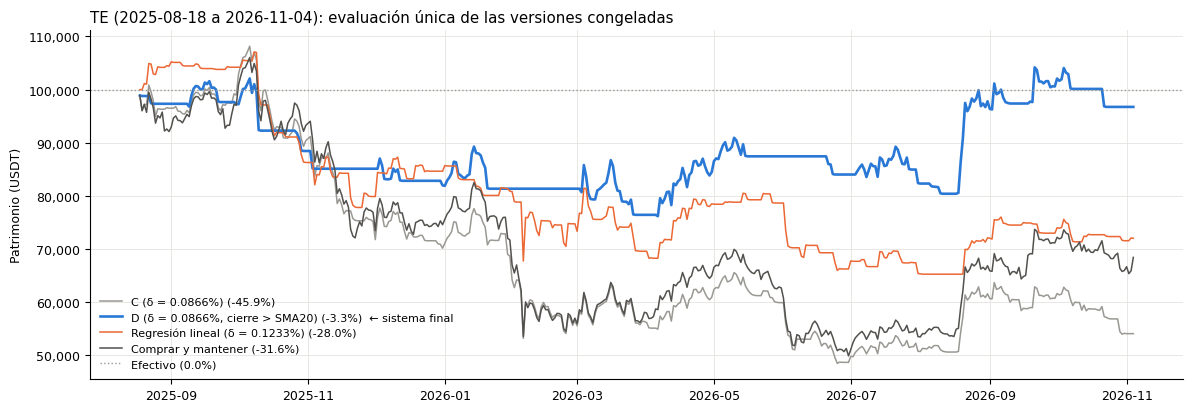

In [32]:
# === 7.2 Patrimonio en TE ===
fig, ax = plt.subplots(figsize=(12, 4.2))
for nombre, sim in SIMS_TE.items():
    if nombre == 'Efectivo':
        continue
    x, y = curva(sim)
    r = TE_EST[TE_EST.estrategia == nombre]['rendimiento_neto'].iloc[0]
    color = AZUL if nombre == nombre_final else (TINTA2 if nombre == 'Comprar y mantener' else NARANJA if nombre.startswith('Regresión') else GRIS)
    ax.plot(x, y, color=color, lw=1.9 if nombre == nombre_final else 1.1, label=f'{nombre} ({r:+.1%})' + ('  ← sistema final' if nombre == nombre_final else ''))
ax.axhline(CONFIG['CAPITAL_INICIAL'], color=GRIS, ls=':', lw=1, label='Efectivo (0.0%)')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:,.0f}')); ax.set_ylabel('Patrimonio (USDT)')
ax.set_title(f"TE ({TE.fecha_objetivo.min().date()} a {TE.fecha_objetivo.max().date()}): evaluación única de las versiones congeladas", loc='left')
ax.legend(frameon=False, fontsize=8, loc='lower left')
fig.tight_layout(); fig.savefig(DIRS['figuras'] / 'cap11_patrimonio_TE.png', dpi=150, bbox_inches='tight'); plt.show()

In [33]:
# === 7.3 Cargar el modelo final y los escaladores desde Drive y repetir predicciones ===
mods = [keras.models.load_model(BASE / c) for c in CONFIG_FINAL['checkpoints']]
escs = {k: joblib.load(DIR_MOD11 / f'escalador_{k}_cap11.joblib') for k in ('A', 'B', 'canales', 'y')}
lags_te, ind_te, seq_te, _ = RAW['TE']
xa = escs['A'].transform(lags_te[:10])
if FINAL == ('lstm', 'B'):
    can = escs['canales'].transform(seq_te[:10, :, 1:].reshape(-1, len(IND))).reshape(10, N, len(IND))
    Xr = np.concatenate([a_secuencia(xa), can.astype('float32')], axis=2)
elif FINAL == ('lstm', 'A'):
    Xr = a_secuencia(xa)
elif FINAL == ('mlp', 'B'):
    Xr = escs['B'].transform(np.hstack([lags_te[:10], ind_te[:10]])).astype('float32')
else:
    Xr = xa.astype('float32')
rep = escs['y'].inverse_transform(predecir(mods, Xr, 'TE').reshape(-1, 1)).ravel()
if not np.allclose(rep, P_FINAL['TE'][:10], rtol=1e-4, atol=1e-7):
    raise ValorInvalidoError('El modelo cargado desde Drive no repite las predicciones.')
print('✔ El modelo final y los escaladores cargados desde Drive repiten las predicciones de TE.')

✔ El modelo final y los escaladores cargados desde Drive repiten las predicciones de TE.


## 8. Pronóstico del siguiente periodo no observado

Se descarga la historia **reciente** de MEXC, **sin modificar** el archivo crudo ni TR, VA y TE. Se aplican la misma auditoría y la misma función de indicadores, se comprueba que los precios coinciden con el archivo congelado en las fechas comunes, y se pronostica el día siguiente al **último cierre completo**. El valor real queda vacío hasta observarse. Si la descarga falla, se usa el último cierre del archivo congelado y se registra en la bitácora.

In [34]:
# === 8. Pronóstico futuro ===
fuente = 'archivo congelado'
dia_f = DIA
if CONFIG['DESCARGAR_DATOS_RECIENTES']:
    try:
        ini = (pd.Timestamp.now(tz='UTC').normalize() - pd.Timedelta(days=CONFIG['DIAS_RECIENTES'])).strftime('%Y-%m-%d')
        rec_raw, info_rec = descargar_klines_mexc(SIM, INTV, ini)
        sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        ruta_rec = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_recientes_{sello}.csv'
        rec_raw.to_csv(ruta_rec, index=False)
        rec, aud_rec, _, _ = auditar(rec_raw, {'descarga_ms': info_rec['descarga_ms']}, 60, CONFIG['HUECO_MAX_DIAS'])
        comun = rec.merge(datos[['fecha', 'close']], on='fecha', suffixes=('', '_congelado'))
        if len(comun) and not np.allclose(comun['close'], comun['close_congelado'], rtol=1e-9):
            registrar_evento('pronóstico futuro', 'Precios recientes distintos al archivo congelado', f'{len(comun)} fechas comunes',
                             'Se usa el archivo congelado para el pronóstico', 'revisar fuente')
        else:
            dia_f = tabla_diaria(rec[['fecha', 'open', 'high', 'low', 'close']])
            fuente = f'descarga reciente de MEXC ({ruta_rec.name}, SHA-256 {sha256_archivo(ruta_rec)[:12]}…); coincide con el archivo congelado en {len(comun)} fechas comunes'
    except (DescargaError, DatosVaciosError, DimensionError, FechaDuplicadaError, ValorInvalidoError) as e:
        registrar_evento('pronóstico futuro', type(e).__name__, str(e)[:150], 'Se usa el último cierre del archivo congelado', 'pronóstico generado')

fecha_corte = dia_f['close'].last_valid_index()
pc = dia_f.index.get_loc(fecha_corte)
ultimos = dia_f.iloc[pc - N + 1: pc + 1]
if len(ultimos) < N or not np.isfinite(ultimos[['ret'] + IND].to_numpy()).all():
    raise DatosVaciosError(f'No hay {N} días completos con indicadores válidos hasta {fecha_corte.date()}: no se puede pronosticar.')
lags_f = ultimos['ret'].to_numpy()[::-1].reshape(1, -1)                    # ret_lag_0 = r del día de corte
ind_f = ultimos[IND].to_numpy()[-1:].reshape(1, -1)
seq_f = ultimos[['ret'] + IND].to_numpy().reshape(1, N, 1 + len(IND))
xa_f = ESC['A'].transform(lags_f)
if FINAL[0] == 'lstm':
    Xf = a_secuencia(xa_f) if FINAL[1] == 'A' else np.concatenate(
        [a_secuencia(xa_f), ESC['canales'].transform(seq_f[:, :, 1:].reshape(-1, len(IND))).reshape(1, N, len(IND)).astype('float32')], axis=2)
else:
    Xf = xa_f.astype('float32') if FINAL[1] == 'A' else ESC['B'].transform(np.hstack([lags_f, ind_f])).astype('float32')
CONJUNTOS_PREDICHOS.add('FUTURO')
y_f = float(yinv(np.mean([np.asarray(m.predict(Xf, verbose=0)).ravel() for m in MOD11[FINAL]], axis=0))[0])
sobre_sma = bool(ultimos['dist_sma20'].iloc[-1] > 0)
senal_f = (y_f > delta_f) and (sobre_sma if ESTRATEGIA_FINAL == 'D' else True)
FUTURO = pd.DataFrame([{'fecha_corte': fecha_corte.date(), 'proximo_periodo': (fecha_corte + pd.Timedelta(days=1)).date(),
                        'rendimiento_estimado': y_f, 'senal': 'comprar' if senal_f else 'efectivo', 'valor_real': '',
                        'modelo': CONFIG_FINAL['modelo_pronostico'] + '_ensamble3', 'estrategia': ESTRATEGIA_FINAL,
                        'delta': delta_f, 'cierre_sobre_SMA20': sobre_sma, 'cierre_en_corte': float(ultimos['close'].iloc[-1]),
                        'fuente_datos': fuente, 'generado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')}])
FUTURO.to_csv(DIRS['resultados'] / 'prediccion_futura.csv', index=False)
print(f"Último cierre completo: {fecha_corte.date()} ({ultimos['close'].iloc[-1]:,.2f} USDT) — fuente: {fuente}")
print(f"Pronóstico para {(fecha_corte + pd.Timedelta(days=1)).date()}: {y_f:+.4%} → señal: {'COMPRAR / mantener comprado' if senal_f else 'EFECTIVO'}")
print('Es una predicción futura, todavía no evaluable: su valor real queda vacío.')
FUTURO.T

  2026-06-15 → 2026-11-12: 151 velas
Último cierre completo: 2026-11-11 (74,007.14 USDT) — fuente: descarga reciente de MEXC (BTCUSDT_1d_mexc_recientes_20261112T142547Z.csv, SHA-256 ff16b9886eec…); coincide con el archivo congelado en 143 fechas comunes
Pronóstico para 2026-11-12: +0.0639% → señal: EFECTIVO
Es una predicción futura, todavía no evaluable: su valor real queda vacío.


,0
fecha_corte,2026-11-11
proximo_periodo,2026-11-12
rendimiento_estimado,0.000639
senal,efectivo
valor_real,
modelo,lstm_A_ensamble3
estrategia,D
delta,0.000866
cierre_sobre_SMA20,False
cierre_en_corte,74007.14


## 9. Seguimiento: ¿el indicador aporta información o solo complejidad? Conclusión sobre la hipótesis técnica

In [35]:
# === 9. Respuesta basada en la evidencia de este notebook ===
lstm_ab = AB[AB.modelo == RED_PRINCIPAL].iloc[0]
lr_ab = AB[AB.modelo == 'lr'].iloc[0]
c_vs_d = ELEC['D']['rendimiento_neto'] - ELEC['C']['rendimiento_neto']
lineas = [
    f"Como VARIABLE (A vs B, VA): en la {RED_PRINCIPAL.upper()} el RMSE cambia {lstm_ab['cambio_RMSE_%']:+.2f} % y el MAE {lstm_ab['cambio_MAE_%']:+.2f} %; "
    f"en la regresión lineal, {lr_ab['cambio_RMSE_%']:+.2f} % y {lr_ab['cambio_MAE_%']:+.2f} %.",
    f"  ¿Mejora más que la variación entre semillas? {'sí' if lstm_ab['mejora_mayor_que_ruido'] else 'no'} → versión elegida: {VERSION[RED_PRINCIPAL]}.",
    f"  Correlación (Spearman, TR) con y_t: dist_sma20 {CORR.loc['dist_sma20', 'y (objetivo)']:+.3f}, vol20 {CORR.loc['vol20', 'y (objetivo)']:+.3f}.",
    f"  vol20 se calcula con los mismos 20 rendimientos que ya ve el modelo: aporta una transformación, no datos nuevos.",
    f"Como FILTRO (C vs D, VA): D cambia el rendimiento neto {100 * c_vs_d:+.2f} puntos porcentuales frente a C, el drawdown de {ELEC['C']['max_drawdown']:.1%} a "
    f"{ELEC['D']['max_drawdown']:.1%} y las operaciones de {int(ELEC['C']['operaciones_cerradas'])} a {int(ELEC['D']['operaciones_cerradas'])}.",
    f"En TE (evaluación única): C {TE_EST.iloc[0]['rendimiento_neto']:+.2%}, D {TE_EST.iloc[1]['rendimiento_neto']:+.2%}, "
    f"comprar y mantener {bh['rendimiento_neto']:+.2%}.",
]
veredicto_var = 'aporta información medible' if lstm_ab['mejora_mayor_que_ruido'] else 'agrega complejidad sin una mejora distinguible del ruido'
veredicto_fil = 'mejora la estrategia en VA' if c_vs_d > 0 else 'no mejora la estrategia en VA'
lineas.append(f"Conclusión: como variable de pronóstico, el indicador {veredicto_var}; como filtro de señal, {veredicto_fil}.")
lineas.append('Hipótesis H1 (Avance 1): "dist_sma20 aporta información sobre y_t y reduce MAE/RMSE en VA" → '
              + ('se sostiene en VA.' if (lstm_ab['cambio_RMSE_%'] < 0 and lstm_ab['mejora_mayor_que_ruido']) else 'no se sostiene en VA (se conserva H0).')
              + ' Ningún resultado confirma ganancias futuras.')
for l in lineas:
    print(l)
with open(DIRS['resultados'] / 'seguimiento_cap11.txt', 'w') as f:
    f.write('\n'.join(lineas))

Como VARIABLE (A vs B, VA): en la LSTM el RMSE cambia +0.19 % y el MAE +0.31 %; en la regresión lineal, -0.12 % y -0.34 %.
  ¿Mejora más que la variación entre semillas? no → versión elegida: A.
  Correlación (Spearman, TR) con y_t: dist_sma20 +0.004, vol20 +0.010.
  vol20 se calcula con los mismos 20 rendimientos que ya ve el modelo: aporta una transformación, no datos nuevos.
Como FILTRO (C vs D, VA): D cambia el rendimiento neto +3.63 puntos porcentuales frente a C, el drawdown de -43.3% a -26.3% y las operaciones de 24 a 20.
En TE (evaluación única): C -45.93%, D -3.25%, comprar y mantener -31.57%.
Conclusión: como variable de pronóstico, el indicador agrega complejidad sin una mejora distinguible del ruido; como filtro de señal, mejora la estrategia en VA.
Hipótesis H1 (Avance 1): "dist_sma20 aporta información sobre y_t y reduce MAE/RMSE en VA" → no se sostiene en VA (se conserva H0). Ningún resultado confirma ganancias futuras.


## 10. Ejecución limpia, entregables y controles finales

In [36]:
# === 10. Lista de comprobación del protocolo ===
R = DIRS['resultados']
entregables = {
    'experimentos.csv': R / 'experimentos.csv', 'predicciones_TE.csv': R / 'predicciones_TE.csv',
    'prediccion_futura.csv': R / 'prediccion_futura.csv', 'simulacion.csv': R / 'simulacion.csv',
    'bitácora de errores': DIRS['bitacora'] / 'bitacora_errores.csv', 'auditoría de datos': R / 'auditoria_datos.csv',
    'diccionario de datos': R / 'diccionario_datos.csv', 'ficha del activo': R / 'ficha_activo.json',
    'datos originales (crudo)': ARCH_CRUDO, 'datos procesados': ARCH_PROC,
    'configuración final congelada': R / 'configuracion_final_congelada.json',
    'modelo final (checkpoints)': BASE / CONFIG_FINAL['checkpoints'][0], 'escaladores finales': DIR_MOD11 / 'escalador_y_cap11.joblib',
    'evidencia T4 (más reciente)': max(DIRS['evidencia'].glob('evidencia_t4_*.json'), key=lambda r: r.stat().st_mtime, default=DIRS['evidencia'] / 'falta'),
}
for nombre, ruta in entregables.items():
    print(('✔' if Path(ruta).exists() else '✘'), f'{nombre:32s}', Path(ruta).relative_to(BASE) if str(ruta).startswith(str(BASE)) else ruta)
exp = pd.read_csv(R / 'experimentos.csv')
controles = {
    'T4 verificada y entrenamientos en GPU': bool(EVIDENCIA_T4.get('T4_OK')) and bool(INFO11['dispositivo_pesos'].str.upper().str.contains('GPU').all()),
    'Indicadores solo con historia hasta t (prueba de alteración futura)': True,
    'A y B evaluados en las mismas fechas de VA': len(Y11['VA']) == len(VA),
    'Escaladores ajustados solo con TR': all(e.n_samples_seen_ in (len(TRc), len(TRc) * N) for e in ESC.values()),
    'Configuración congelada antes de TE (SHA-256)': (R / 'configuracion_final_congelada.json').exists(),
    'TE evaluado una sola vez (registro)': RUTA_LOG_TE.exists(),
    'Pronóstico futuro con valor real vacío': FUTURO['valor_real'].iloc[0] == '',
    'Capítulos registrados en experimentos.csv': ', '.join(map(str, sorted(exp['capitulo'].dropna().astype(int).unique()))),
    'Conjuntos sobre los que se predijo': ', '.join(sorted(CONJUNTOS_PREDICHOS)),
}
print()
for k, v in controles.items():
    print(('✔' if v is True else '✘' if v is False else '•'), k, '' if isinstance(v, bool) else f': {v}')
json.dump(controles, open(R / 'controles_cap11.json', 'w'), indent=2, ensure_ascii=False, default=str)

✔ experimentos.csv                 resultados/experimentos.csv
✔ predicciones_TE.csv              resultados/predicciones_TE.csv
✔ prediccion_futura.csv            resultados/prediccion_futura.csv
✔ simulacion.csv                   resultados/simulacion.csv
✔ bitácora de errores              bitacora/bitacora_errores.csv
✔ auditoría de datos               resultados/auditoria_datos.csv
✔ diccionario de datos             resultados/diccionario_datos.csv
✔ ficha del activo                 resultados/ficha_activo.json
✔ datos originales (crudo)         datos/originales/BTCUSDT_1d_mexc_crudo.csv
✔ datos procesados                 datos/procesados/BTCUSDT_1d_procesado.csv
✔ configuración final congelada    resultados/configuracion_final_congelada.json
✔ modelo final (checkpoints)       modelos/cap11/cap11_lstm_A_n20_s42.keras
✔ escaladores finales              modelos/cap11/escalador_y_cap11.joblib
✔ evidencia T4 (más reciente)      evidencia_t4/evidencia_t4_20261112T142444Z.json

✔ T4 veri

## 11. Reflexión del capítulo 11 y conclusión

- **Qué hicimos:** Incorporamos indicadores técnicos como variables adicionales para evaluar si mejoraban los pronósticos de los modelos. Utilizamos la distancia a la SMA de 20 días (`dist_sma20`) y la volatilidad de 20 rendimientos (`vol20`). Comparamos dos versiones de los modelos: A, que utiliza únicamente los 20 rendimientos anteriores, y B, que incorpora los indicadores. También comparamos dos estrategias de inversión: C, basada únicamente en el pronóstico, y D, que además utiliza el filtro de que el precio de cierre esté por encima de la SMA20. Finalmente, seleccionamos una configuración utilizando VA, la congelamos y realizamos una única evaluación en TE.

- **Por qué:** El objetivo fue comprobar si los indicadores técnicos aportan información adicional para mejorar la capacidad predictiva de los modelos y si pueden ayudar a obtener mejores resultados al tomar decisiones de inversión. También buscamos evitar la fuga de información, utilizando únicamente datos históricos disponibles hasta cada fecha y reservando TE para la evaluación final.

- **Evidencia obtenida:** Los indicadores se calcularon utilizando información histórica hasta el día correspondiente, sin rellenar los valores faltantes hacia atrás. En la comparación A vs B, la LSTM presentó un incremento de 0.19 % en RMSE y de 0.31 % en MAE al incorporar los indicadores, por lo que no obtuvo una mejora. La regresión lineal sí presentó pequeñas reducciones de 0.12 % en RMSE y 0.34 % en MAE, mientras que la MLP empeoró. Por ello, se seleccionó la versión A de la LSTM, ya que la incorporación de indicadores no produjo una mejora superior a la variación entre semillas. En la comparación de estrategias en VA, la estrategia C obtuvo un rendimiento neto de 47.54 %, mientras que D alcanzó 51.17 %. Además, D redujo el drawdown de -43.31 % a -26.29 % y las operaciones cerradas de 24 a 20. Después de congelar la configuración, la evaluación en TE mostró un rendimiento neto de -3.25 % para D, frente a -45.93 % para C, -27.98 % para la regresión lineal y -31.57 % para comprar y mantener.

- **¿El indicador aporta información o solo complejidad?:** Como variable adicional para pronosticar rendimientos, los indicadores no demostraron aportar una mejora significativa. En particular, la LSTM obtuvo peores resultados al incorporarlos y la mejora de la regresión lineal fue muy pequeña. Además, las correlaciones de Spearman de `dist_sma20` y `vol20` con el rendimiento objetivo fueron de 0.004 y 0.010, respectivamente, lo que indica una relación prácticamente nula. Sin embargo, como filtro de operación, la SMA20 sí mostró utilidad en VA, ya que permitió mejorar el rendimiento y reducir el drawdown de la estrategia. Por lo tanto, su utilidad parece estar más relacionada con la confirmación de señales que con la mejora directa del pronóstico.

- **Conclusión sobre la hipótesis del estudio técnico:** La hipótesis H1, que establece que la distancia a la SMA20 aporta información sobre el rendimiento futuro y reduce los errores MAE y RMSE en VA, no se sostiene con los resultados obtenidos. Por lo tanto, se conserva H0. Aunque el filtro SMA20 mejoró los resultados de la estrategia en VA y también superó a comprar y mantener en TE, esto no demuestra que el indicador permita predecir mejor los rendimientos ni garantiza ganancias futuras.

- **Limitaciones:** Los resultados dependen de un solo activo (BTC/USDT) y de un periodo específico de evaluación. Además, se utilizó un costo de operación supuesto de 0.10 %, sin modelar completamente el deslizamiento ni la liquidez del mercado. La ejecución se simuló en la apertura del día siguiente, utilizando como precio de referencia el cierre anterior, lo que puede diferir de las condiciones reales de operación en MEXC. También debe considerarse que el resultado negativo de la estrategia final en TE muestra que el desempeño observado en VA no garantiza que la estrategia sea rentable en otros periodos.

- **Qué cambiaríamos después:** Como siguiente paso, utilizaríamos el entorno de aprendizaje por refuerzo desarrollado en el Avance 4 para entrenar una política mediante DQN o DDQN. Compararíamos el agente con las estrategias de referencia, incluyendo la estrategia D con filtro SMA20, y evaluaríamos si puede aprender a considerar el pronóstico, la tendencia, los costos y la posición actual. Finalmente, probaríamos la política seleccionada con datos nuevos e independientes, sin modificarla después de observar los resultados.